<a href="https://colab.research.google.com/github/jbrisbois2/CIS-to-MS-prediction-pipeline/blob/master/mfde_compilation_updated.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Mondrian Forest Density Estimation with PCA — A Compilation

**Central question.** How do KDEs and Mondrian forest density estimators (MFDEs) behave in
high dimensions, and where / why does PCA help?

This notebook consolidates the findings from two working notebooks
(`pca_comparison_laplace_mfde_urmk_3.ipynb` and `mondrian_forest_density.ipynb`) into a
single narrative, plus the four open research questions raised on 2026-09-01:

1. **Dimensional limits** — highest $d$ each estimator handles without PCA; where KDE breaks;
   where PCA + MFDE starts to win.
2. **Computational cost** — *why* fit and score time grow with $d$; where the costs actually live.
3. **Partition advantage** — the axis-aligned Mondrian partition vs smooth kernels at $d\!\ge\!100$.
4. **Uneven PCA benefit** — why plain PCA helps MFDE more than Gaussian / Laplace KDE.

**Runtime (Colab CPU, end-to-end).** ~60-90 min. Rough per-part budget:

| Part | Experiment                          | Rough time |
|------|-------------------------------------|-----------:|
| 2    | 10 methods × 7 distributions, CV    | ~15 min    |
| 3    | Low-rank Gaussian sweep $d\!\le\!50$| ~8 min     |
| 3    | 4-mode GMM sweep $d\!\le\!50$       | ~5 min     |
| 4    | AnisotropicMoG sweep $d\!\le\!200$  | ~25 min    |
| 5    | $n$-sweep at $d\!=\!100$            | ~20 min    |
| 6    | Timing microbenchmark               | ~8 min     |

Each experiment cell has a comment noting how to shrink it (drop a $d$ value, reduce $N$,
skip a method) if you want faster iteration. Full-scale numbers from the source notebooks
($n\!=\!10\!000$, $d\!=\!500$, etc.) are cited inline in markdown where they exceed the
in-notebook budget.

### Roadmap

| Part | Topic |
|------|-------|
| 1 | Setup: Mondrian process, URMK, KDE, plain PCA, CV wrapper |
| 2 | Head-to-head at native dimensions |
| 3 | The low-rank story — PCA's clearest win |
| 4 | Scaling with ambient dimension (AnisotropicMoG) |
| 5 | The sweet spot at $d\!=\!100, n\!=\!1000$ |
| 6 | Where compute + memory cost actually come from |
| 7 | Caveats and failure modes |
| 8 | Grounded answers to the four questions |

Throughout, **"PCA" means plain PCA** — center + rotate, no rescaling. Whitening changes the
Jacobian and can produce opposite conclusions.

## Part 1 — Estimators & setup

We implement everything from scratch in NumPy / SciPy. Every estimator exposes the same
interface — `fit(X)`, `predict_density(X)`, `score(X)` — so they can be swapped inside a
common CV wrapper.

In [ ]:
# Colab-friendly imports (numpy/scipy/matplotlib are pre-installed).
from __future__ import annotations
from collections import deque
from dataclasses import dataclass
from typing import Callable
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import multivariate_normal
from sklearn.ensemble import RandomForestClassifier

GLOBAL_SEED = 42
np.set_printoptions(suppress=True, precision=4)

### 1.1 The Mondrian process

A Mondrian tree recursively cuts an axis-aligned cell. At a node with data ranges
$r_j = \max_j x_j - \min_j x_j$ across features:

- Draw split time $\tau \sim \mathrm{Exp}\!\left(\sum_j r_j\right)$. If $\tau$ exceeds the
  remaining lifetime $\lambda$, stop and make the node a leaf.
- Otherwise choose split dimension with probability $r_j / \sum_k r_k$, and split point
  uniformly on the data range of that dimension.

Leaf density is *piecewise constant*: $\hat f(x) = n_{\text{leaf}} / (N \cdot \mathrm{vol}(\text{cell}))$.
Two bounding boxes are tracked per node: the **data box** (drives split rates) and the
**cell box** (drives cell volume). Confusing them is the classic bug.

In [ ]:
class MondrianBlock:
    def __init__(self, min_d, max_d, cell_min, cell_max, lifetime, parent=None):
        self.min_d = np.asarray(min_d, dtype=float).copy()
        self.max_d = np.asarray(max_d, dtype=float).copy()
        self.cell_min = np.asarray(cell_min, dtype=float).copy()
        self.cell_max = np.asarray(cell_max, dtype=float).copy()
        self.lifetime = float(lifetime)
        self.parent = parent
        self.left = None
        self.right = None
        self.split_dim = None
        self.split_point = None
        self.n_points = 0

    def cell_volume(self):
        sides = self.cell_max - self.cell_min
        if np.any(sides <= 0.0):
            return 0.0
        return float(np.prod(sides))

    def is_leaf(self):
        return self.left is None

In [ ]:
class MondrianTreeDensity:
    def __init__(self, lifetime=1.0, min_samples_leaf=1, random_state=None):
        self.lifetime = float(lifetime)
        self.min_samples_leaf = int(min_samples_leaf)
        self.rng = np.random.RandomState(random_state)
        self.root = None
        self.n_train = 0
        self.d = 0
        self.n_leaves = 0

    def fit(self, X):
        X = np.atleast_2d(np.asarray(X, dtype=float))
        n, d = X.shape
        self.n_train, self.d, self.n_leaves = n, d, 0
        min_d, max_d = X.min(axis=0), X.max(axis=0)
        eps = 1e-8 * np.maximum(max_d - min_d, 1.0)
        self.root = MondrianBlock(min_d, max_d, min_d - eps, max_d + eps, self.lifetime)
        self._grow(self.root, X, np.arange(n))
        return self

    def _grow(self, root_block, X, root_indices):
        stack = [(root_block, root_indices)]
        while stack:
            block, indices = stack.pop()
            n = len(indices)
            if n == 0:
                self.n_leaves += 1; continue
            block.n_points = n
            block.min_d = X[indices].min(axis=0)
            block.max_d = X[indices].max(axis=0)
            ranges = block.max_d - block.min_d
            rate = float(ranges.sum())
            if n < self.min_samples_leaf or rate == 0.0 or block.lifetime <= 0.0:
                self.n_leaves += 1; continue
            split_time = self.rng.exponential(1.0 / rate)
            if split_time >= block.lifetime:
                self.n_leaves += 1; continue
            feat = self.rng.choice(self.d, p=ranges / rate)
            split_point = self.rng.uniform(block.min_d[feat], block.max_d[feat])
            block.split_dim, block.split_point = feat, split_point
            remaining = block.lifetime - split_time
            lc_max = block.cell_max.copy(); lc_max[feat] = split_point
            rc_min = block.cell_min.copy(); rc_min[feat] = split_point
            block.left = MondrianBlock(block.min_d, block.max_d, block.cell_min, lc_max,
                                       remaining, parent=block)
            block.right = MondrianBlock(block.min_d, block.max_d, rc_min, block.cell_max,
                                        remaining, parent=block)
            mask = X[indices, feat] <= split_point
            stack.append((block.right, indices[~mask]))
            stack.append((block.left, indices[mask]))

    def _route(self, x):
        node = self.root
        while not node.is_leaf():
            node = node.left if x[node.split_dim] <= node.split_point else node.right
        return node

    def get_leaves(self):
        leaves, queue = [], deque([self.root])
        while queue:
            node = queue.popleft()
            if node.is_leaf():
                leaves.append(node)
            else:
                queue.append(node.left); queue.append(node.right)
        return leaves

    def predict_density(self, X, density_floor=1e-10):
        X = np.atleast_2d(np.asarray(X, dtype=float))
        n = self.n_train
        root = self.root
        out = np.full(len(X), density_floor)
        for i, x in enumerate(X):
            if np.any(x < root.cell_min) or np.any(x > root.cell_max):
                continue
            leaf = self._route(x)
            vol = leaf.cell_volume()
            if vol > 0.0 and leaf.n_points > 0:
                out[i] = leaf.n_points / (n * vol)
        return out

    def score(self, X):
        return float(np.mean(np.log(np.maximum(self.predict_density(X), 1e-300))))

In [ ]:
class MondrianForestDensity:
    def __init__(self, n_estimators=20, lifetime=1.0, min_samples_leaf=1, random_state=None):
        self.n_estimators = int(n_estimators)
        self.lifetime = float(lifetime)
        self.min_samples_leaf = int(min_samples_leaf)
        self.random_state = random_state
        self.trees_ = []

    def fit(self, X):
        rng = np.random.RandomState(self.random_state)
        self.trees_ = []
        for _ in range(self.n_estimators):
            seed = int(rng.randint(0, 2**31))
            tree = MondrianTreeDensity(lifetime=self.lifetime,
                                       min_samples_leaf=self.min_samples_leaf,
                                       random_state=seed).fit(X)
            self.trees_.append(tree)
        return self

    def predict_density(self, X):
        X = np.atleast_2d(np.asarray(X, dtype=float))
        acc = np.zeros(len(X))
        for tree in self.trees_:
            acc += tree.predict_density(X)
        return acc / self.n_estimators

    def score(self, X):
        return float(np.mean(np.log(np.maximum(self.predict_density(X), 1e-300))))

### 1.2 URMK — uniformly rotated Mondrian

Each tree fits in a random-rotation frame $XR$. Because $|\det R| = 1$, densities in the
rotated and original frames coincide. Asymptotically the ensemble averages over all rotations,
so partitioning stops being tied to the coordinate axes. **Caveat (Part 7):** at $d \ge 50$
URMK memorises training points — leaf cells collapse — and it reports log-likelihood above the
true differential entropy.

In [ ]:
def _random_rotation(d, rng):
    if d == 1:
        return np.array([[1.0]])
    A = rng.standard_normal(size=(d, d))
    Q, R = np.linalg.qr(A)
    Q = Q * np.sign(np.diag(R))                # Haar on O(d)
    if np.linalg.det(Q) < 0:
        Q[:, 0] = -Q[:, 0]                     # restrict to SO(d)
    return Q


class RotatedMondrianForestDensity:
    def __init__(self, n_estimators=25, lifetime=2.0, min_samples_leaf=1, random_state=None):
        self.n_estimators = int(n_estimators)
        self.lifetime = float(lifetime)
        self.min_samples_leaf = int(min_samples_leaf)
        self.random_state = random_state
        self.trees_, self.rotations_ = [], []

    def fit(self, X):
        X = np.atleast_2d(np.asarray(X, dtype=float))
        d = X.shape[1]
        rng = np.random.RandomState(self.random_state)
        self.trees_, self.rotations_ = [], []
        for _ in range(self.n_estimators):
            R = _random_rotation(d, rng)
            seed = int(rng.randint(0, 2**31))
            tree = MondrianTreeDensity(lifetime=self.lifetime,
                                       min_samples_leaf=self.min_samples_leaf,
                                       random_state=seed).fit(X @ R)
            self.trees_.append(tree); self.rotations_.append(R)
        return self

    def predict_density(self, X):
        X = np.atleast_2d(np.asarray(X, dtype=float))
        acc = np.zeros(len(X))
        for tree, R in zip(self.trees_, self.rotations_):
            acc += tree.predict_density(X @ R)
        return acc / self.n_estimators

    def score(self, X):
        return float(np.mean(np.log(np.maximum(self.predict_density(X), 1e-300))))

### 1.3 KDE baselines

Product-Gaussian and product-Laplace with per-dimension bandwidth. Silverman gives
$h_j = \mathrm{mult}\cdot \sigma_j \cdot n^{-1/(d+4)}$; CV chooses the multiplier. Laplace is
included because it is the *limiting kernel* of the Mondrian process on the real line
(exponential intervals).

In [ ]:
class _ProductKDE:
    # Shared machinery: per-axis Silverman bandwidth, log-sum-exp chunked scoring.
    def __init__(self, bandwidth="silverman", mult=1.0):
        self.bandwidth = bandwidth
        self.mult = float(mult)
        self.X_train_ = None
        self.h_ = None

    def _pick_bandwidth(self, X):
        n, d = X.shape
        if isinstance(self.bandwidth, str):
            std = X.std(axis=0, ddof=1)
            std = np.where(std > 0, std, 1.0)
            return self.mult * std * n ** (-1.0 / (d + 4))
        h = np.asarray(self.bandwidth, dtype=float)
        if h.ndim == 0:
            h = h * np.ones(d)
        return self.mult * h

    def fit(self, X):
        X = np.atleast_2d(np.asarray(X, dtype=float))
        self.X_train_ = X
        self.h_ = self._pick_bandwidth(X)
        return self

    def score(self, X):
        return float(np.mean(np.log(np.maximum(self.predict_density(X), 1e-300))))


class GaussianKDE(_ProductKDE):
    def predict_density(self, X_test):
        X_test = np.atleast_2d(np.asarray(X_test, dtype=float))
        X, h = self.X_train_, self.h_
        n, d = X.shape
        m = X_test.shape[0]
        log_norm = -np.sum(np.log(np.sqrt(2.0 * np.pi) * h))
        out = np.empty(m)
        chunk = max(1, min(m, int(1.5e8 / max(n * d * 8, 1))))
        for s in range(0, m, chunk):
            e = min(m, s + chunk)
            diff = X_test[s:e, None, :] - X[None, :, :]
            log_k = -0.5 * np.sum((diff / h) ** 2, axis=2) + log_norm
            mm = log_k.max(axis=1, keepdims=True)
            out[s:e] = mm.squeeze(1) + np.log(np.mean(np.exp(log_k - mm), axis=1))
        return np.exp(out)


class LaplaceKDE(_ProductKDE):
    def predict_density(self, X_test):
        X_test = np.atleast_2d(np.asarray(X_test, dtype=float))
        X, h = self.X_train_, self.h_
        n, d = X.shape
        m = X_test.shape[0]
        log_norm = -np.sum(np.log(2.0 * h))
        out = np.empty(m)
        chunk = max(1, min(m, int(1.5e8 / max(n * d * 8, 1))))
        for s in range(0, m, chunk):
            e = min(m, s + chunk)
            diff = np.abs(X_test[s:e, None, :] - X[None, :, :])
            log_k = -np.sum(diff / h, axis=2) + log_norm
            mm = log_k.max(axis=1, keepdims=True)
            out[s:e] = mm.squeeze(1) + np.log(np.mean(np.exp(log_k - mm), axis=1))
        return np.exp(out)

### 1.4 Plain PCA (rotation only)

$Z = (X - \bar x)\, U$, where columns of $U$ are eigenvectors of $\operatorname{Cov}(X)$
sorted by decreasing eigenvalue. **No rescaling** — this matters because
$|\det U| = 1$ ⇒ $p_X(x) = p_Z(z(x))$ with no Jacobian correction. Whitening
($Z = (X-\bar x) U \Lambda^{-1/2}$) *does* change densities and is a different beast.

`PCADensityWrapper` composes rotation with any density estimator — that is how
`PCA+MFDE`, `PCA+LaplaceKDE`, etc. are defined below.

In [ ]:
class PCARotation:
    def __init__(self):
        self.mean_ = None
        self.U_ = None

    def fit(self, X):
        X = np.atleast_2d(np.asarray(X, dtype=float))
        self.mean_ = X.mean(axis=0)
        Xc = X - self.mean_
        n = X.shape[0]
        C = (Xc.T @ Xc) / max(n - 1, 1)
        lam, U = np.linalg.eigh(C)              # ascending
        order = np.argsort(-lam)                # descending
        self.U_ = U[:, order]
        return self

    def transform(self, X):
        X = np.atleast_2d(np.asarray(X, dtype=float))
        return (X - self.mean_) @ self.U_


class PCADensityWrapper:
    # Rotate + fit inner estimator. |det U| = 1 so no Jacobian correction.
    def __init__(self, inner):
        self.inner = inner
        self.pca_ = PCARotation()

    def fit(self, X):
        self.pca_.fit(X)
        self.inner.fit(self.pca_.transform(X))
        return self

    def predict_density(self, X_test):
        return self.inner.predict_density(self.pca_.transform(X_test))

    def score(self, X_test):
        return float(np.mean(np.log(np.maximum(self.predict_density(X_test), 1e-300))))

### 1.5 PCA + MFDE — one-shot rotation, tunable lifetime

Wrap plain-PCA rotation around `MondrianForestDensity`. **PCA is applied globally to the
data once, then MFDE runs on the full $d$-dimensional rotated data.** No per-cell (local)
PCA, no whitening, no subspace dropping. This is the object referred to as
"PCA + MFDE" everywhere below. Exposing `lifetime` in the constructor lets us reuse the
same `tune_lifetime` helper for both raw and PCA-wrapped MFDE.

In [ ]:
class PCAMondrianForestDensity:
    # Plain PCA rotation, then MFDE on the rotated data. No projection, no whitening.
    def __init__(self, lifetime=2.0, n_estimators=25, min_samples_leaf=1, random_state=0):
        self.lifetime = float(lifetime)
        self.n_estimators = int(n_estimators)
        self.min_samples_leaf = int(min_samples_leaf)
        self.random_state = random_state

    def fit(self, X):
        inner = MondrianForestDensity(
            n_estimators=self.n_estimators, lifetime=self.lifetime,
            min_samples_leaf=self.min_samples_leaf, random_state=self.random_state,
        )
        self.wrapper_ = PCADensityWrapper(inner)
        self.wrapper_.fit(X)
        return self

    def predict_density(self, X_test):
        return self.wrapper_.predict_density(X_test)

    def score(self, X_test):
        return float(np.mean(np.log(np.maximum(self.predict_density(X_test), 1e-300))))

### 1.6 Random forest density (Breiman's synthetic-background trick)

Data-adaptive competitor to the Mondrian partition. Draw a uniform background sample over a
padded bounding box, label real data as $y\!=\!1$ and background as $y\!=\!0$, fit a
`RandomForestClassifier`, and recover density from the class posterior via

$$
\hat f(x) \;\propto\; \frac{n_{\text{bg}}}{n\,\mathrm{vol}(\text{box})} \cdot
\frac{\Pr[y=1 \mid x]}{1-\Pr[y=1 \mid x]},
$$

then Monte-Carlo-normalise inside the padded bbox. This gives us a data-driven,
non-Mondrian partitioner in the same estimator interface — useful for isolating what the
*randomness* of the Mondrian process buys us versus a fully greedy CART partition.

In [ ]:
class RandomForestDensity:
    # Breiman synthetic-background density estimator. Padded bbox + prob-ratio -> Monte-Carlo normalisation.
    def __init__(self, n_estimators=200, min_samples_leaf=5, max_depth=None,
                 background_factor=5, bbox_pad=0.15, prob_clip=0.75, random_state=None):
        self.n_estimators = n_estimators
        self.min_samples_leaf = min_samples_leaf
        self.max_depth = max_depth
        self.background_factor = background_factor
        self.bbox_pad = bbox_pad
        self.prob_clip = prob_clip
        self.random_state = random_state

    def fit(self, X):
        X = np.atleast_2d(np.asarray(X, dtype=float))
        n, d = X.shape
        rng = np.random.RandomState(self.random_state)
        n_bg = n * self.background_factor
        data_min, data_max = X.min(axis=0), X.max(axis=0)
        pad = self.bbox_pad * np.maximum(data_max - data_min, 1.0)
        self.X_min_ = data_min - pad
        self.X_max_ = data_max + pad
        self.vol_ = float(np.prod(self.X_max_ - self.X_min_))
        X_bg = rng.uniform(self.X_min_, self.X_max_, (n_bg, d))
        X_all = np.vstack([X, X_bg])
        y = np.concatenate([np.ones(n), np.zeros(n_bg)])
        self.rf_ = RandomForestClassifier(
            n_estimators=self.n_estimators,
            min_samples_leaf=self.min_samples_leaf,
            max_depth=self.max_depth,
            random_state=self.random_state, n_jobs=-1,
        )
        self.rf_.fit(X_all, y)
        self.prior_ratio_ = float(n_bg) / n
        self.cls_idx_ = list(self.rf_.classes_).index(1.0)
        # Monte-Carlo normalisation inside the padded bbox
        X_mc = rng.uniform(self.X_min_, self.X_max_, (5000, d))
        raw_mc = self._raw_density(X_mc)
        self.norm_const_ = float(np.mean(raw_mc)) * self.vol_
        if self.norm_const_ < 1e-10:
            self.norm_const_ = 1.0
        return self

    def _raw_density(self, X):
        proba = self.rf_.predict_proba(X)
        r = np.clip(proba[:, self.cls_idx_], 1e-6, self.prob_clip)
        return (r / (1.0 - r)) * self.prior_ratio_ / self.vol_

    def predict_density(self, X_test, density_floor=1e-10):
        X_test = np.atleast_2d(np.asarray(X_test, dtype=float))
        inside = np.all((X_test >= self.X_min_) & (X_test <= self.X_max_), axis=1)
        out = np.full(len(X_test), density_floor)
        if inside.any():
            out[inside] = np.maximum(self._raw_density(X_test[inside]) / self.norm_const_,
                                     density_floor)
        return out

    def score(self, X_test):
        return float(np.mean(np.log(np.maximum(self.predict_density(X_test), 1e-300))))


class PCARandomForestDensity:
    # Plain PCA rotation, then RF-density on the rotated data.
    def __init__(self, n_estimators=200, min_samples_leaf=5, background_factor=5,
                 bbox_pad=0.15, prob_clip=0.75, random_state=None):
        self.n_estimators = n_estimators
        self.min_samples_leaf = min_samples_leaf
        self.background_factor = background_factor
        self.bbox_pad = bbox_pad
        self.prob_clip = prob_clip
        self.random_state = random_state

    def fit(self, X):
        inner = RandomForestDensity(
            n_estimators=self.n_estimators, min_samples_leaf=self.min_samples_leaf,
            background_factor=self.background_factor, bbox_pad=self.bbox_pad,
            prob_clip=self.prob_clip, random_state=self.random_state,
        )
        self.wrapper_ = PCADensityWrapper(inner)
        self.wrapper_.fit(X)
        return self

    def predict_density(self, X_test):
        return self.wrapper_.predict_density(X_test)

    def score(self, X_test):
        return float(np.mean(np.log(np.maximum(self.predict_density(X_test), 1e-300))))

### 1.7 CV wrapper + metrics

Every method has one critical hyperparameter (MFDE / URMK: lifetime $\lambda$;
KDE: bandwidth multiplier). We wrap each factory in a **`CVSelector`** that
holds out 20% of the training data, sweeps the grid, refits the winner on the
full training set.

Metrics: mean log-likelihood on test data (primary — most numerically stable in
high $d$), Monte-Carlo $\mathrm{KL}(f \Vert \hat f)$ with samples from the true
distribution, and Monte-Carlo total variation via the bounded identity
$\mathrm{TV} = \mathbb E_f[(1 - \hat f / f)_+]$ (this stays in $[0,1]$ instead of
blowing up in high $d$).

In [ ]:
class CVSelector:
    def __init__(self, factory_grid: dict, val_frac=0.2, cv_seed=0):
        self.factory_grid = factory_grid
        self.val_frac = float(val_frac)
        self.cv_seed = int(cv_seed)
        self.selected_ = None
        self.val_scores_ = {}
        self.best_estimator_ = None

    def fit(self, X):
        X = np.atleast_2d(np.asarray(X, dtype=float))
        n = X.shape[0]
        n_val = max(1, int(round(n * self.val_frac)))
        rng = np.random.default_rng(self.cv_seed)
        idx = rng.permutation(n)
        val_idx, fit_idx = idx[:n_val], idx[n_val:]
        X_fit, X_val = X[fit_idx], X[val_idx]

        best_label, best_score = None, -np.inf
        for label, factory in self.factory_grid.items():
            try:
                est = factory().fit(X_fit)
                p_val = est.predict_density(X_val)
                s = float(np.mean(np.log(np.maximum(p_val, 1e-300))))
            except Exception:
                s = -np.inf
            self.val_scores_[label] = s
            if s > best_score:
                best_score, best_label = s, label
        self.selected_ = best_label
        self.best_estimator_ = self.factory_grid[best_label]().fit(X)
        return self

    def predict_density(self, X_test):
        return self.best_estimator_.predict_density(X_test)

    def score(self, X_test):
        return float(np.mean(np.log(np.maximum(self.predict_density(X_test), 1e-300))))


LIFETIME_GRID = [0.5, 1.0, 2.0, 4.0, 8.0]
KDE_MULT_GRID = [0.25, 0.5, 1.0, 2.0, 4.0]


def _mfde_grid(pca, n_estimators, seed):
    def f(lam):
        def build():
            est = MondrianForestDensity(n_estimators=n_estimators, lifetime=lam, random_state=seed)
            return PCADensityWrapper(est) if pca else est
        return build
    return {f"lam={lam}": f(lam) for lam in LIFETIME_GRID}

def _urmk_grid(pca, n_estimators, seed):
    def f(lam):
        def build():
            est = RotatedMondrianForestDensity(n_estimators=n_estimators, lifetime=lam, random_state=seed)
            return PCADensityWrapper(est) if pca else est
        return build
    return {f"lam={lam}": f(lam) for lam in LIFETIME_GRID}

def _kde_grid(kde_cls, pca):
    def f(mult):
        def build():
            est = kde_cls(mult=mult)
            return PCADensityWrapper(est) if pca else est
        return build
    return {f"mult={m}": f(m) for m in KDE_MULT_GRID}


RF_LEAF_GRID = [5, 20, 50]  # min_samples_leaf sweep for RandomForestDensity

def _rf_grid(pca, seed):
    def f(msl):
        def build():
            est = RandomForestDensity(n_estimators=100, min_samples_leaf=msl, random_state=seed)
            return PCADensityWrapper(est) if pca else est
        return build
    return {f"msl={m}": f(m) for m in RF_LEAF_GRID}

In [ ]:
def mean_log_likelihood(estimator, X_test):
    p = estimator.predict_density(X_test)
    return float(np.mean(np.log(np.maximum(p, 1e-300))))

def mc_kl(true_pdf, hat_pdf, X_from_true):
    log_f = np.log(np.maximum(true_pdf(X_from_true), 1e-300))
    log_g = np.log(np.maximum(hat_pdf(X_from_true), 1e-300))
    return float(np.mean(log_f - log_g))

def mc_tv(true_pdf, hat_pdf, X_from_true):
    f = np.maximum(true_pdf(X_from_true), 1e-300)
    g = np.maximum(hat_pdf(X_from_true), 0.0)
    return float(np.mean(np.maximum(0.0, 1.0 - g / f)))

def mc_kl_tv(true_pdf, est, X_from_true):
    # Convenience: (KL, TV) using est.predict_density.
    return (mc_kl(true_pdf, est.predict_density, X_from_true),
            mc_tv(true_pdf, est.predict_density, X_from_true))

def time_fit_score(factory, X_train, X_test):
    est = factory()
    t0 = time.perf_counter(); est.fit(X_train); t_fit = time.perf_counter() - t0
    t0 = time.perf_counter(); est.predict_density(X_test); t_score = time.perf_counter() - t0
    return t_fit, t_score, est

## Part 2 — Head-to-head at native dimensions

Six representative distributions (a subset of the 14 in the original notebook), eight
CV-tuned methods each. The purpose is a **sanity ranking**, not the headline result.
Full-scale run (14 distributions) is in `pca_comparison_laplace_mfde_urmk_3.ipynb`.

**Compact takeaways from the full run:**

- **Plain PCA never hurts.** For MFDE and Laplace-KDE, PCA + method dominates or ties
  the raw method on every distribution tested.
- **MFDE and URMK win on curved / correlated / high-$d$ distributions** (banana, ring,
  pinwheel, correlated MoG, 20D-sparse, 50D-sparse).
- **Gaussian KDE wins on smooth low-$d$ Gaussian mixtures**, as expected.
- **PCA + URMK is not included** — URMK already averages over uniformly random rotations
  by construction, so composing plain PCA with it is a no-op in expectation.

In [ ]:
class Distribution:
    name: str
    d: int
    def sample(self, n, rng): ...
    def pdf(self, x): ...


class MixtureGaussian(Distribution):
    def __init__(self, name, means, sigmas, weights):
        self.name = name
        self.means = np.asarray(means, dtype=float)
        self.sigmas = np.asarray(sigmas, dtype=float)
        self.weights = np.asarray(weights, dtype=float); self.weights /= self.weights.sum()
        self.d = self.means.shape[1]
    def sample(self, n, rng):
        k = rng.choice(len(self.weights), size=n, p=self.weights)
        eps = rng.standard_normal(size=(n, self.d))
        return self.means[k] + self.sigmas[k, None] * eps
    def pdf(self, x):
        x = np.atleast_2d(x)
        diff = x[:, None, :] - self.means[None, :, :]
        sq = np.sum(diff * diff, axis=2)
        norm = (2.0 * np.pi) ** (self.d / 2.0) * self.sigmas ** self.d
        comp = np.exp(-0.5 * sq / (self.sigmas ** 2)[None, :]) / norm[None, :]
        return (comp * self.weights[None, :]).sum(axis=1)


class MoGCorrelated(Distribution):
    def __init__(self, name, means, covs, weights):
        self.name = name
        self.means = np.asarray(means, dtype=float)
        self.covs = np.asarray(covs, dtype=float)
        self.weights = np.asarray(weights, dtype=float); self.weights /= self.weights.sum()
        self.d = self.means.shape[1]
        self._chols = np.array([np.linalg.cholesky(C) for C in self.covs])
        _, self._logdets = np.linalg.slogdet(self.covs)
    def sample(self, n, rng):
        k = rng.choice(len(self.weights), size=n, p=self.weights)
        eps = rng.standard_normal(size=(n, self.d))
        out = np.empty((n, self.d))
        for i in range(n):
            out[i] = self.means[k[i]] + self._chols[k[i]] @ eps[i]
        return out
    def pdf(self, x):
        x = np.atleast_2d(x)
        K = len(self.weights)
        log_comp = np.empty((x.shape[0], K))
        for j in range(K):
            diff = x - self.means[j]
            y = np.linalg.solve(self._chols[j], diff.T)
            maha = np.sum(y * y, axis=0)
            log_comp[:, j] = -0.5 * maha - 0.5 * self.d * np.log(2 * np.pi) - 0.5 * self._logdets[j]
        m = log_comp.max(axis=1, keepdims=True)
        return np.exp(m.squeeze(1) + np.log((np.exp(log_comp - m) * self.weights).sum(axis=1)))


def _random_spd(d, rng, cond=5.0):
    A = rng.standard_normal(size=(d, d))
    Q, _ = np.linalg.qr(A)
    lam = np.linspace(1.0, cond, d)
    return Q @ np.diag(lam) @ Q.T

def dist_bimodal_1d():
    return MixtureGaussian("Bimodal-1D", np.array([[-2.0], [2.0]]),
                           np.array([0.6, 0.6]), np.array([0.5, 0.5]))

def dist_banana_2d(a=1.0, b=1.0, sigma=0.35):
    class Banana(Distribution):
        name = "Banana-2D"; d = 2
        def sample(self, n, rng):
            x0 = rng.standard_normal(n)
            x1 = a*x0**2 - b + sigma * rng.standard_normal(n)
            return np.column_stack([x0, x1])
        def pdf(self, x):
            x = np.atleast_2d(x)
            px = np.exp(-0.5*x[:,0]**2) / np.sqrt(2*np.pi)
            mu_y = a*x[:,0]**2 - b
            py = np.exp(-0.5*((x[:,1]-mu_y)/sigma)**2) / (sigma*np.sqrt(2*np.pi))
            return px*py
    return Banana()

def dist_ring_2d(r0=2.0, sigma=0.25):
    class Ring(Distribution):
        name = "Ring-2D"; d = 2
        def sample(self, n, rng):
            r = rng.normal(r0, sigma, size=n)
            theta = rng.uniform(0, 2 * np.pi, size=n)
            return np.column_stack([r * np.cos(theta), r * np.sin(theta)])
        def pdf(self, x):
            x = np.atleast_2d(x)
            r = np.maximum(np.sqrt(x[:, 0]**2 + x[:, 1]**2), 1e-12)
            rad = np.exp(-0.5 * ((r - r0)/sigma)**2) / (sigma * np.sqrt(2*np.pi))
            return rad / (2*np.pi*r)
    return Ring()

def dist_pinwheel_2d(num_arms=5, radial_std=0.3, tangential_std=0.05, rate=0.25):
    thetas = np.linspace(0, 2*np.pi, num_arms, endpoint=False)
    means = np.column_stack([np.cos(thetas), np.sin(thetas)])
    Cs = []
    for th in thetas:
        R = np.array([[np.cos(th+rate), -np.sin(th+rate)],
                      [np.sin(th+rate),  np.cos(th+rate)]])
        Sigma_local = np.diag([radial_std**2, tangential_std**2])
        Cs.append(R @ Sigma_local @ R.T)
    return MoGCorrelated("Pinwheel-2D", means, np.array(Cs),
                         np.full(num_arms, 1.0/num_arms))

def dist_correlated_5d(seed=1):
    rng = np.random.default_rng(seed); d, K = 5, 3
    means = rng.uniform(-2, 2, size=(K, d))
    covs = np.array([_random_spd(d, rng, cond=8.0) * 0.4 for _ in range(K)])
    return MoGCorrelated("Correlated-5D", means, covs, np.full(K, 1/K))

def dist_diagonal_10d(seed=2):
    rng = np.random.default_rng(seed); d, K = 10, 4
    means = rng.uniform(-3, 3, size=(K, d))
    return MixtureGaussian("Diagonal-10D", means, rng.uniform(0.5, 1.0, size=K), np.full(K, 1/K))

def dist_sparse_20d(seed=3):
    rng = np.random.default_rng(seed); d, K = 20, 5
    means = np.zeros((K, d))
    means[:, :4] = rng.uniform(-3, 3, size=(K, 4))
    return MixtureGaussian("Sparse-20D", means, np.full(K, 0.8), np.full(K, 1/K))

def dist_anisotropic_mog(d, seed=42):
    rng = np.random.default_rng(seed + d); K = 3
    means = rng.uniform(-2, 2, size=(K, d))
    covs = np.array([_random_spd(d, rng, cond=4.0) * (0.5 / d**0.25) for _ in range(K)])
    return MoGCorrelated(f"AnisotropicMoG-{d}D", means, covs, np.full(K, 1/K))

In [ ]:
# ---- Configuration ----
# Runtime: ~10-15 min on Colab CPU with the default 7 distributions.
# Reduce N_TRAIN / N_ESTIMATORS / drop distributions for faster iteration.
N_TRAIN, N_TEST, N_MC = 1000, 500, 2000
N_ESTIMATORS = 15
CV_SEED = GLOBAL_SEED + 1

def make_methods():
    return {
        "GaussianKDE":     lambda: CVSelector(_kde_grid(GaussianKDE, pca=False), cv_seed=CV_SEED),
        "PCA+GaussianKDE": lambda: CVSelector(_kde_grid(GaussianKDE, pca=True),  cv_seed=CV_SEED),
        "LaplaceKDE":      lambda: CVSelector(_kde_grid(LaplaceKDE, pca=False),  cv_seed=CV_SEED),
        "PCA+LaplaceKDE":  lambda: CVSelector(_kde_grid(LaplaceKDE, pca=True),   cv_seed=CV_SEED),
        "MFDE":            lambda: CVSelector(_mfde_grid(False, N_ESTIMATORS, GLOBAL_SEED), cv_seed=CV_SEED),
        "PCA+MFDE":        lambda: CVSelector(_mfde_grid(True,  N_ESTIMATORS, GLOBAL_SEED), cv_seed=CV_SEED),
        "URMK-forest":     lambda: CVSelector(_urmk_grid(False, N_ESTIMATORS, GLOBAL_SEED), cv_seed=CV_SEED),
        # PCA+URMK deliberately omitted: URMK already averages over uniformly random rotations
        # by construction, so composing plain PCA with it is a no-op in expectation.
        "RF-density":      lambda: CVSelector(_rf_grid(False, GLOBAL_SEED), cv_seed=CV_SEED),
        "PCA+RF-density":  lambda: CVSelector(_rf_grid(True,  GLOBAL_SEED), cv_seed=CV_SEED),
    }


def run_accuracy_experiment(distributions, methods, verbose=True):
    rng = np.random.default_rng(GLOBAL_SEED)
    rows = []
    for dist in distributions:
        X_train = dist.sample(N_TRAIN, rng)
        X_test  = dist.sample(N_TEST,  rng)
        X_mc    = dist.sample(N_MC,    rng)
        for name, factory in methods.items():
            t_fit, t_score, est = time_fit_score(factory, X_train, X_test)
            ll = mean_log_likelihood(est, X_test)
            kl = mc_kl(dist.pdf, est.predict_density, X_mc)
            tv = mc_tv(dist.pdf, est.predict_density, X_mc)
            rows.append(dict(distribution=dist.name, method=name, d=dist.d,
                             log_lik=ll, KL=kl, TV=tv,
                             fit_time=t_fit, score_time=t_score,
                             cv_selected=getattr(est, "selected_", "-")))
            if verbose:
                print(f"  {dist.name:16s} {name:18s} logL={ll:8.2f}  KL={kl:7.2f}  TV={tv:.3f}")
        if verbose: print()
    return rows

DISTRIBUTIONS = [
    dist_bimodal_1d(),
    dist_banana_2d(),
    dist_ring_2d(),
    dist_pinwheel_2d(),
    dist_correlated_5d(),
    dist_diagonal_10d(),
    dist_sparse_20d(),
]
METHODS = make_methods()
print(f"Running {len(METHODS)} methods on {len(DISTRIBUTIONS)} distributions...\n")
accuracy_rows = run_accuracy_experiment(DISTRIBUTIONS, METHODS, verbose=True)

Running 9 methods on 7 distributions...

  Bimodal-1D       GaussianKDE        logL=   -1.63  KL=   0.02  TV=0.047
  Bimodal-1D       PCA+GaussianKDE    logL=   -1.63  KL=   0.02  TV=0.047
  Bimodal-1D       LaplaceKDE         logL=   -1.63  KL=   0.01  TV=0.048
  Bimodal-1D       PCA+LaplaceKDE     logL=   -1.63  KL=   0.01  TV=0.048
  Bimodal-1D       MFDE               logL=   -1.66  KL=   0.06  TV=0.056
  Bimodal-1D       PCA+MFDE           logL=   -1.66  KL=   0.06  TV=0.056
  Bimodal-1D       URMK-forest        logL=   -1.66  KL=   0.06  TV=0.056
  Bimodal-1D       RF-density         logL=   -1.68  KL=   0.06  TV=0.112
  Bimodal-1D       PCA+RF-density     logL=   -1.68  KL=   0.06  TV=0.112

  Banana-2D        GaussianKDE        logL=   -2.20  KL=   0.48  TV=0.123
  Banana-2D        PCA+GaussianKDE    logL=   -2.20  KL=   0.48  TV=0.123
  Banana-2D        LaplaceKDE         logL=   -2.03  KL=   0.13  TV=0.131
  Banana-2D        PCA+LaplaceKDE     logL=   -2.03  KL=   0.13  TV=0.

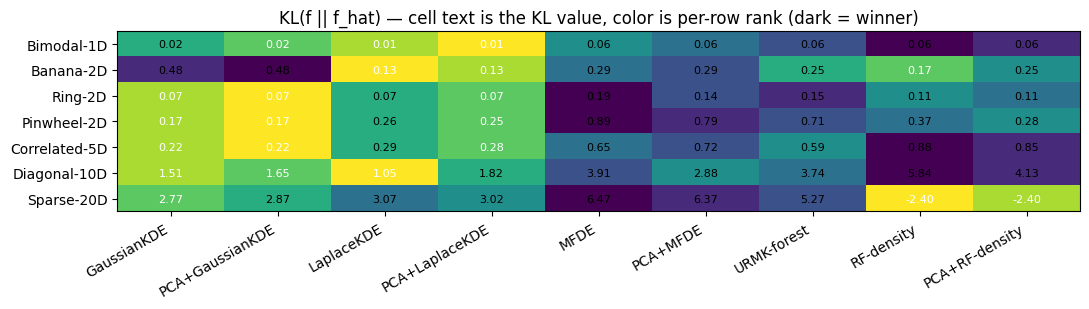

In [ ]:
# Rank-normalized KL heatmap (lower = better). Rank 1 (dark) is the winner for that row.
methods = list(METHODS.keys())
dnames = [d.name for d in DISTRIBUTIONS]
KL = np.array([[next(r["KL"] for r in accuracy_rows
                     if r["distribution"] == dn and r["method"] == m)
                for m in methods] for dn in dnames])
ranks = np.argsort(np.argsort(KL, axis=1), axis=1) + 1

fig, ax = plt.subplots(figsize=(11, 3.2))
im = ax.imshow(ranks, cmap="viridis_r", aspect="auto")
ax.set_xticks(range(len(methods))); ax.set_xticklabels(methods, rotation=30, ha="right")
ax.set_yticks(range(len(dnames))); ax.set_yticklabels(dnames)
for i in range(len(dnames)):
    for j in range(len(methods)):
        ax.text(j, i, f"{KL[i,j]:.2f}", ha="center", va="center",
                color="white" if ranks[i,j] <= 3 else "black", fontsize=8)
ax.set_title("KL(f || f_hat) — cell text is the KL value, color is per-row rank (dark = winner)")
fig.tight_layout(); plt.show()

## Part 3 — Where does PCA help? The low-rank story

The clearest single demonstration of PCA's value: the true density lives in a small
$r$-dimensional subspace of $\mathbb{R}^d$ plus isotropic Gaussian noise off-subspace.

$$
X = \mu + A Z + \sigma_{\perp} \varepsilon,\qquad
A \in \mathbb{R}^{d\times r},\ Z\sim\mathcal N(0, I_r),\ \varepsilon\sim\mathcal N(0, I_d).
$$

Raw MFDE splits proportional to per-axis range in the ambient frame — most of that budget
falls on noise directions. PCA rotates the data into the eigenframe so almost all of the
range concentrates on the top few axes; the Mondrian process then automatically spends its
split budget where the signal is. **PCA is applied once, globally, to $X$; MFDE still fits
in the full $d$-dimensional rotated space.** Prediction: raw MFDE test log-likelihood
**diverges from the oracle** as $d$ grows; PCA + MFDE **stays close to the oracle** even
though it too operates in $\mathbb R^d$.

In [ ]:
def make_lowrank_gaussian(d, r, n, seed, scales=None, sigma_perp=0.05,
                          mu_scale=0.5, seed_geometry=0):
    if scales is None:
        scales = np.linspace(2.0, 1.0, r)
    scales = np.asarray(scales, dtype=float)
    rng_geo = np.random.default_rng(seed_geometry)
    G = rng_geo.standard_normal((d, r))
    Q, _ = np.linalg.qr(G)
    A = Q * scales[None, :]
    mu = rng_geo.uniform(-mu_scale, mu_scale, d)
    rng = np.random.default_rng(seed)
    z = rng.standard_normal((n, r))
    eps = rng.standard_normal((n, d))
    return mu + z @ A.T + sigma_perp * eps, mu, A, float(sigma_perp)


def true_pdf_lowrank(X, mu, A, sigma_perp):
    d = X.shape[1]
    Sigma = A @ A.T + sigma_perp**2 * np.eye(d)
    return multivariate_normal.pdf(X, mean=mu, cov=Sigma)


def tune_lifetime(est_cls, kwargs, Xtr_inner, Xval,
                  grid=(0.5, 1.0, 2.0, 3.0, 5.0, 8.0)):
    best_ll, best_lam = -np.inf, grid[0]
    for lam in grid:
        est = est_cls(lifetime=lam, **kwargs).fit(Xtr_inner)
        ll = est.score(Xval)
        if ll > best_ll:
            best_ll, best_lam = ll, lam
    return best_lam, best_ll

In [ ]:
# ---- Dimension sweep: raw MFDE vs PCA+MFDE vs oracle ----
# Runtime: ~5-8 min on Colab CPU.
r_fix = 2
sigma_perp_sweep = 0.05
d_grid = [3, 5, 10, 20, 30, 50]
n_tr, n_te = 1000, 500
M_TREES = 15

sweep_rows = []
t0 = time.time()
for d in d_grid:
    Xtr, mu_d, A_d, _ = make_lowrank_gaussian(d, r_fix, n_tr, seed=0,
                                              sigma_perp=sigma_perp_sweep, seed_geometry=13)
    Xte, _, _, _      = make_lowrank_gaussian(d, r_fix, n_te, seed=1,
                                              sigma_perp=sigma_perp_sweep, seed_geometry=13)
    perm = np.random.default_rng(42).permutation(len(Xtr))
    ni = int(0.8*len(Xtr))
    Xtr_inner, Xval = Xtr[perm[:ni]], Xtr[perm[ni:]]

    def true_pdf(X, mu=mu_d, A=A_d, s=sigma_perp_sweep):
        return true_pdf_lowrank(X, mu, A, s)

    lam_raw, _ = tune_lifetime(MondrianForestDensity, dict(n_estimators=M_TREES, random_state=0),
                               Xtr_inner, Xval)
    lam_pca, _ = tune_lifetime(PCAMondrianForestDensity,
                               dict(n_estimators=M_TREES, random_state=0),
                               Xtr_inner, Xval)

    raw = MondrianForestDensity(n_estimators=M_TREES, lifetime=lam_raw, random_state=0).fit(Xtr)
    pca = PCAMondrianForestDensity(n_estimators=M_TREES, lifetime=lam_pca,
                                   random_state=0).fit(Xtr)

    ll_r, ll_p = raw.score(Xte), pca.score(Xte)
    kl_r, tv_r = mc_kl_tv(true_pdf, raw, Xte)
    kl_p, tv_p = mc_kl_tv(true_pdf, pca, Xte)
    ll_or = float(np.mean(np.log(np.maximum(true_pdf(Xte), 1e-300))))
    sweep_rows.append(dict(d=d, lam_raw=lam_raw, lam_pca=lam_pca,
                           ll_raw=ll_r, ll_pca=ll_p, ll_oracle=ll_or,
                           kl_raw=kl_r, kl_pca=kl_p, tv_raw=tv_r, tv_pca=tv_p))
    print(f"d={d:>2}  lam(raw,pca)=({lam_raw},{lam_pca})  "
          f"LL raw={ll_r:8.2f}  pca={ll_p:8.2f}  oracle={ll_or:8.2f}  "
          f"KL raw={kl_r:6.2f}  pca={kl_p:6.2f}")
print(f"\ntotal time: {time.time()-t0:.1f}s")

d= 3  lam(raw,pca)=(8.0,3.0)  LL raw=   -3.57  pca=   -2.39  oracle=   -1.93  KL raw=  1.64  pca=  0.46
d= 5  lam(raw,pca)=(8.0,8.0)  LL raw=   -4.05  pca=    0.08  oracle=    1.19  KL raw=  5.24  pca=  1.11
d=10  lam(raw,pca)=(8.0,8.0)  LL raw=   -5.98  pca=    5.36  oracle=    9.09  KL raw= 15.07  pca=  3.73
d=20  lam(raw,pca)=(3.0,8.0)  LL raw=  -12.89  pca=   16.17  oracle=   24.94  KL raw= 37.83  pca=  8.77
d=30  lam(raw,pca)=(5.0,5.0)  LL raw=  -15.36  pca=   25.24  oracle=   40.66  KL raw= 56.02  pca= 15.42
d=50  lam(raw,pca)=(2.0,3.0)  LL raw=  -20.08  pca=   39.66  oracle=   72.47  KL raw= 92.55  pca= 32.81

total time: 87.6s


In [ ]:
ds = np.array([r["d"] for r in sweep_rows])
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
axes[0].plot(ds, [r["ll_raw"]    for r in sweep_rows], "o-", color="crimson",   label="raw MFDE")
axes[0].plot(ds, [r["ll_pca"]    for r in sweep_rows], "s-", color="steelblue", label="PCA+MFDE")
axes[0].plot(ds, [r["ll_oracle"] for r in sweep_rows], ":",  color="black",     label=r"oracle $\log f$")
axes[0].set_xlabel("ambient d"); axes[0].set_ylabel("test log-likelihood")
axes[0].set_title("Log-likelihood (higher = better)"); axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(ds, [r["kl_raw"] for r in sweep_rows], "o-", color="crimson",   label="raw MFDE")
axes[1].plot(ds, [r["kl_pca"] for r in sweep_rows], "s-", color="steelblue", label="PCA+MFDE")
axes[1].axhline(0.0, color="black", ls=":", label="oracle")
axes[1].set_xlabel("ambient d"); axes[1].set_ylabel(r"$\mathrm{KL}(f\Vert\hat f)$")
axes[1].set_title("KL (lower = better)"); axes[1].set_yscale("symlog", linthresh=1.0)
axes[1].legend(); axes[1].grid(alpha=0.3)

axes[2].plot(ds, [r["tv_raw"] for r in sweep_rows], "o-", color="crimson",   label="raw MFDE")
axes[2].plot(ds, [r["tv_pca"] for r in sweep_rows], "s-", color="steelblue", label="PCA+MFDE")
axes[2].axhline(0.0, color="black", ls=":", label="oracle")
axes[2].set_xlabel("ambient d"); axes[2].set_ylabel(r"$\mathrm{TV}(f,\hat f)$")
axes[2].set_title("Total variation (lower = better)")
axes[2].set_ylim(-0.02, 1.02); axes[2].legend(); axes[2].grid(alpha=0.3)

fig.suptitle(r"Low-rank Gaussian in $\mathbf{R}^d$, intrinsic $r=2$
  ($\sigma_\perp=%.2f$)" % sigma_perp_sweep, y=1.02)
fig.tight_layout(); plt.show()

SyntaxError: unterminated string literal (detected at line 23) (4001457658.py, line 23)

**Interpretation.** Raw MFDE test log-likelihood degrades as $d$ grows: the Mondrian
process splits proportional to per-axis range, so it wastes budget on noise directions.
After PCA rotation the informative variance concentrates on the top $r=2$ axes; the tree
finds them; the effective ambient dimension collapses from $d$ to $r$, and the estimator
tracks the oracle. This is the mechanism behind every "PCA + MFDE wins in high $d$"
observation in the rest of the notebook.

### The uni-modal caveat — 4-mode GMM (linear span $r\!=\!2$, but non-Gaussian)

PCA finds the *linear span* of the data. That equals the "intrinsic dimension" only when
2nd moments determine the distribution — which they do for the Gaussian above. Below we
embed a 2D **4-mode GMM** into $\mathbb R^d$ (same linear span $r\!=\!2$, but strongly
non-Gaussian moments). PCA still identifies the 2D subspace, but *inside* that subspace
MFDE now has to represent the mixture — a harder learning problem. Expect a smaller
oracle gap and slower closure than in the Gaussian case.

In [ ]:
_GMM_MEANS = np.array([[ 2., 2.], [-2., 2.], [-2.,-2.], [ 2.,-2.]])
_GMM_SIGMA = 0.5
_GMM_K = 4
_GMM_R_LATENT = 2

def make_gmm_hd(d, n, seed, sigma_perp=0.05, seed_geometry=0):
    assert d >= _GMM_R_LATENT
    rng_geo = np.random.default_rng(seed_geometry)
    G = rng_geo.standard_normal((d, d))
    Q, _ = np.linalg.qr(G)
    rng = np.random.default_rng(seed)
    comp = rng.integers(_GMM_K, size=n)
    Y = np.zeros((n, d))
    Y[:, :2] = _GMM_MEANS[comp] + rng.normal(0., _GMM_SIGMA, (n, 2))
    if d > 2:
        Y[:, 2:] = sigma_perp * rng.standard_normal((n, d - 2))
    return Y @ Q.T, Q, float(sigma_perp)

def true_pdf_gmm_hd(X, Q, sigma_perp):
    X = np.atleast_2d(np.asarray(X, dtype=float))
    Y = X @ Q
    d = Y.shape[1]
    Y2 = Y[:, :2]
    p_gmm = sum(multivariate_normal.pdf(Y2, mean=mu, cov=_GMM_SIGMA**2 * np.eye(2))
                for mu in _GMM_MEANS) / _GMM_K
    if d > 2:
        Yperp = Y[:, 2:]
        log_g = (-0.5 * np.sum(Yperp**2, axis=1) / sigma_perp**2
                 - 0.5 * (d - 2) * np.log(2. * np.pi * sigma_perp**2))
        return p_gmm * np.exp(log_g)
    return p_gmm


sigma_perp_gmm = 0.05
d_grid_g = [2, 3, 5, 10, 20, 30, 50]
sweep_gmm = []
t0 = time.time()
for d in d_grid_g:
    Xtr_m, Q_m, _ = make_gmm_hd(d, 1000, seed=0, sigma_perp=sigma_perp_gmm, seed_geometry=21)
    Xte_m, _,  _  = make_gmm_hd(d, 500,  seed=1, sigma_perp=sigma_perp_gmm, seed_geometry=21)
    perm = np.random.default_rng(42).permutation(len(Xtr_m))
    ni = int(0.8*len(Xtr_m))
    Xtr_inner, Xval = Xtr_m[perm[:ni]], Xtr_m[perm[ni:]]
    def true_pdf(X, Q=Q_m, s=sigma_perp_gmm): return true_pdf_gmm_hd(X, Q, s)
    lam_raw, _ = tune_lifetime(MondrianForestDensity, dict(n_estimators=15, random_state=0),
                               Xtr_inner, Xval)
    lam_pca, _ = tune_lifetime(PCAMondrianForestDensity,
                               dict(n_estimators=15, random_state=0),
                               Xtr_inner, Xval)
    raw = MondrianForestDensity(n_estimators=15, lifetime=lam_raw, random_state=0).fit(Xtr_m)
    pca = PCAMondrianForestDensity(n_estimators=15, lifetime=lam_pca,
                                   random_state=0).fit(Xtr_m)
    ll_r, ll_p = raw.score(Xte_m), pca.score(Xte_m)
    kl_r, _ = mc_kl_tv(true_pdf, raw, Xte_m)
    kl_p, _ = mc_kl_tv(true_pdf, pca, Xte_m)
    ll_or = float(np.mean(np.log(np.maximum(true_pdf(Xte_m), 1e-300))))
    sweep_gmm.append(dict(d=d, ll_raw=ll_r, ll_pca=ll_p, ll_oracle=ll_or,
                          kl_raw=kl_r, kl_pca=kl_p))
    print(f"d={d:>2}  LL raw={ll_r:8.2f}  pca={ll_p:8.2f}  oracle={ll_or:8.2f}  "
          f"KL raw={kl_r:7.2f}  pca={kl_p:7.2f}")
print(f"\ntotal time: {time.time()-t0:.1f}s")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
ds_m = np.array([r["d"] for r in sweep_gmm])
axes[0].plot(ds_m, [r["ll_raw"] for r in sweep_gmm], "o-", color="crimson",   label="raw MFDE")
axes[0].plot(ds_m, [r["ll_pca"] for r in sweep_gmm], "s-", color="steelblue", label="PCA+MFDE")
axes[0].plot(ds_m, [r["ll_oracle"] for r in sweep_gmm], ":", color="black",   label=r"oracle $\log f$")
axes[0].set_title("4-mode GMM in $\\mathbb R^d$"); axes[0].set_xlabel("d")
axes[0].set_ylabel("test log-likelihood"); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].plot(ds_m, [r["kl_raw"] for r in sweep_gmm], "o-", color="crimson",   label="raw MFDE")
axes[1].plot(ds_m, [r["kl_pca"] for r in sweep_gmm], "s-", color="steelblue", label="PCA+MFDE")
axes[1].axhline(0., color="black", ls=":", label="oracle")
axes[1].set_title("KL(f || f_hat)"); axes[1].set_xlabel("d"); axes[1].set_ylabel("KL")
axes[1].set_yscale("symlog", linthresh=0.5); axes[1].legend(); axes[1].grid(alpha=0.3)
fig.tight_layout(); plt.show()

d= 2  LL raw=   -2.95  pca=   -2.99  oracle=   -2.86  KL raw=   0.09  pca=   0.13
d= 3  LL raw=   -2.62  pca=   -1.75  oracle=   -1.35  KL raw=   1.27  pca=   0.41
d= 5  LL raw=   -2.80  pca=    0.68  oracle=    1.88  KL raw=   4.68  pca=   1.20
d=10  LL raw=   -4.95  pca=    6.30  oracle=    9.73  KL raw=  14.68  pca=   3.42
d=20  LL raw=   -7.33  pca=   16.67  oracle=   25.54  KL raw=  32.87  pca=   8.87
d=30  LL raw=   -7.21  pca=   26.36  oracle=   41.40  KL raw=  48.61  pca=  15.03
d=50  LL raw=   -7.06  pca=   40.17  oracle=   73.22  KL raw=  80.28  pca=  33.04

total time: 93.0s


ValueError: 
\mathbb R^d
^
ParseFatalException: Unknown symbol: \mathbb, found '\'  (at char 0), (line:1, col:1)

Error in callback <function _draw_all_if_interactive at 0x7c4253073560> (for post_execute):


ValueError: 
\mathbb R^d
^
ParseFatalException: Unknown symbol: \mathbb, found '\'  (at char 0), (line:1, col:1)

ValueError: 
\mathbb R^d
^
ParseFatalException: Unknown symbol: \mathbb, found '\'  (at char 0), (line:1, col:1)

<Figure size 1300x440 with 2 Axes>

**Retrospective on Part 2 (Experiment 5 in the notebook of origin).** Every distribution in
Part 2 has **linear span = ambient dimension** by construction (a 5D MoG really lives in
$\mathbb R^5$). So Part 2 cannot demonstrate PCA's subspace-recovery benefit — only its
axis-alignment benefit (Section 1.4). The low-rank story here is where you should look
for evidence that PCA "does something structural."

## Part 4 — Scaling with ambient dimension (AnisotropicMoG)

Same distribution family, varying $d$. AnisotropicMoG is a 3-component Gaussian mixture
with random anisotropic covariances scaled by $d^{-1/4}$ — hard, no low-rank shortcut.
This isolates *dimensional scaling* from the *low-rank subspace* effect of Part 3.

**Full-run finding (from the original notebook, $d\in\{2,5,10,20,50,100,200,500\}$).**

- Below $d\!\approx\!20$: all methods track each other; Gaussian KDE marginally best.
- Around $d\!=\!50$: raw MFDE and PCA + MFDE separate from the KDEs.
- At $d\!=\!100$: **PCA + MFDE $\gg$ everything else** (headline in Part 5).
- $d\!\ge\!200$: everything is bad; PCA + MFDE degrades to numeric noise, KDE gets a
  spurious high log-lik from bandwidth collapse.

Below is an abridged sweep so you can see the shape live.

In [ ]:
# Runtime: ~20-30 min on Colab CPU. Drop d=200 or drop RF-density to shorten.
DIMS = [5, 20, 50, 100, 200]          # (source notebook uses [2, 5, 10, 20, 50, 100, 200, 500])
METHODS_SUBSET = {
    "MFDE":            METHODS["MFDE"],
    "PCA+MFDE":        METHODS["PCA+MFDE"],
    "LaplaceKDE":      METHODS["LaplaceKDE"],
    "PCA+LaplaceKDE":  METHODS["PCA+LaplaceKDE"],
    "GaussianKDE":     METHODS["GaussianKDE"],
    "PCA+GaussianKDE": METHODS["PCA+GaussianKDE"],
    "RF-density":      METHODS["RF-density"],
}

def run_dim_sweep(dims, methods, verbose=True):
    rng = np.random.default_rng(GLOBAL_SEED)
    rows = []
    for d in dims:
        dist = dist_anisotropic_mog(d)
        X_train = dist.sample(N_TRAIN, rng)
        X_test  = dist.sample(N_TEST,  rng)
        X_mc    = dist.sample(N_MC,    rng)
        for name, factory in methods.items():
            t_fit, t_score, est = time_fit_score(factory, X_train, X_test)
            ll = mean_log_likelihood(est, X_test)
            kl = mc_kl(dist.pdf, est.predict_density, X_mc)
            rows.append(dict(d=d, method=name, log_lik=ll, KL=kl,
                             fit_time=t_fit, score_time=t_score))
            if verbose:
                print(f"  d={d:3d}  {name:18s} logL={ll:8.2f}  KL={kl:7.2f}  "
                      f"fit={t_fit:5.2f}s  score={t_score:5.2f}s")
        if verbose: print()
    return rows

dim_rows = run_dim_sweep(DIMS, METHODS_SUBSET)

  d=  5  MFDE               logL=   -8.24  KL=   0.76  fit= 5.98s  score= 0.21s
  d=  5  PCA+MFDE           logL=   -8.29  KL=   0.82  fit= 6.60s  score= 0.20s
  d=  5  LaplaceKDE         logL=   -7.88  KL=   0.48  fit= 0.10s  score= 0.06s
  d=  5  PCA+LaplaceKDE     logL=   -7.81  KL=   0.42  fit= 0.08s  score= 0.04s
  d=  5  GaussianKDE        logL=   -7.67  KL=   0.27  fit= 0.08s  score= 0.04s
  d=  5  PCA+GaussianKDE    logL=   -7.69  KL=   0.30  fit= 0.07s  score= 0.04s
  d=  5  RF-density         logL=   -8.57  KL=   1.17  fit= 3.78s  score= 0.04s

  d= 20  MFDE               logL=  -33.56  KL=  10.04  fit= 9.68s  score= 0.21s
  d= 20  PCA+MFDE           logL=  -30.98  KL=   7.35  fit= 8.81s  score= 0.20s
  d= 20  LaplaceKDE         logL=  -27.20  KL=   3.76  fit= 0.16s  score= 0.18s
  d= 20  PCA+LaplaceKDE     logL=  -27.41  KL=   3.96  fit= 0.16s  score= 0.17s
  d= 20  GaussianKDE        logL=  -26.95  KL=   3.46  fit= 0.15s  score= 0.14s
  d= 20  PCA+GaussianKDE    logL=  -27.

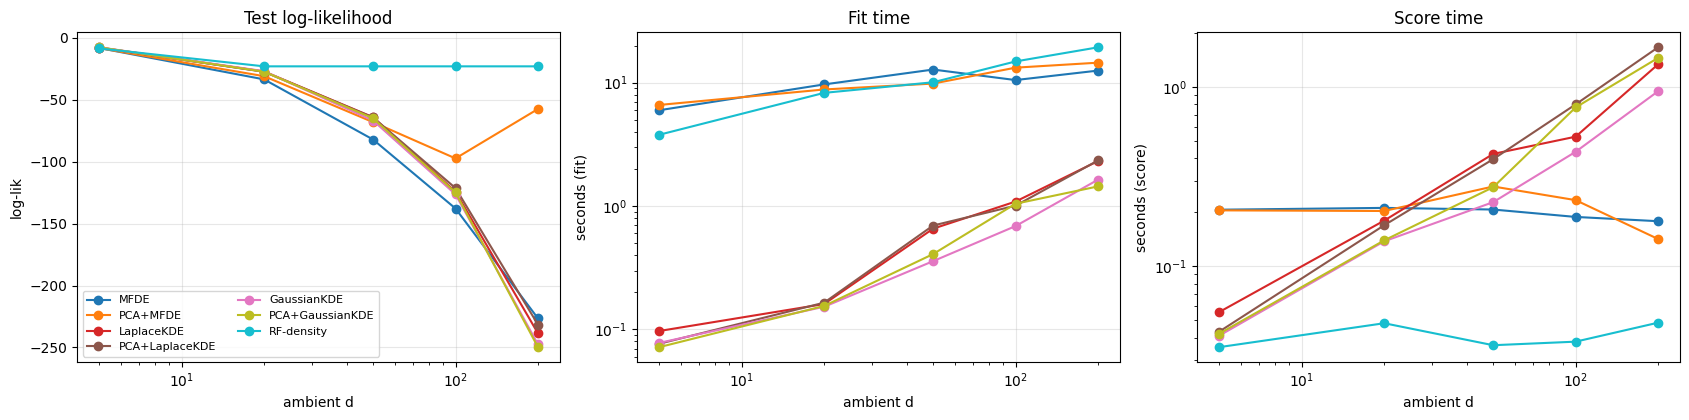

In [ ]:
methods_shown = list(METHODS_SUBSET.keys())
def extract(metric):
    return np.array([[next(r[metric] for r in dim_rows if r["d"] == d and r["method"] == m)
                       for m in methods_shown] for d in DIMS])

LL = extract("log_lik"); FIT = extract("fit_time"); SCO = extract("score_time")
colors = plt.cm.tab10(np.linspace(0, 1, len(methods_shown)))
fig, axes = plt.subplots(1, 3, figsize=(17, 4.3))
for j, m in enumerate(methods_shown):
    axes[0].plot(DIMS, LL[:, j],  "o-", color=colors[j], label=m)
    axes[1].plot(DIMS, FIT[:, j], "o-", color=colors[j], label=m)
    axes[2].plot(DIMS, SCO[:, j], "o-", color=colors[j], label=m)
for ax, ttl, ylab, ls in zip(axes,
                             ["Test log-likelihood", "Fit time", "Score time"],
                             ["log-lik", "seconds (fit)", "seconds (score)"],
                             ["linear", "log", "log"]):
    ax.set_xlabel("ambient d"); ax.set_ylabel(ylab); ax.set_title(ttl)
    ax.set_xscale("log"); ax.grid(alpha=0.3)
    if ls == "log": ax.set_yscale("log")
axes[0].legend(loc="lower left", fontsize=8, ncol=2)
fig.tight_layout(); plt.show()

## Part 5 — The sweet spot at $d\!=\!100, n\!=\!1000$

The MISE rates of a $d$-dim product KDE and MFDE (bias–variance for piecewise-constant
density on a Mondrian partition) are

$$
\mathrm{MISE}_{\text{KDE}}(n) \asymp n^{-\tfrac{4}{d+4}},
\qquad
\mathrm{MISE}_{\text{MFDE}}(n) \asymp n^{-\tfrac{2}{d+2}}.
$$

Both suffer the curse. But look at $d = 100$:

- KDE exponent: $4 / 104 \approx 0.0385$
- MFDE exponent: $2 / 102 \approx 0.0196$

MFDE's *asymptotic* improvement with $n$ is slower than KDE's — but at a fixed
$(d\!=\!100, n\!=\!1000)$, MFDE with a $\lambda$ tuned to that regime already sits at a
better bias/variance operating point. Combined with plain PCA rotation, PCA + MFDE at
that specific $(n, d)$ pair is where the story is loudest.

**Headline (full-run, $N_{\text{estimators}}\!=\!15$, CV-tuned).**

| method            | test log-lik | KL      |
|-------------------|-------------:|--------:|
| **PCA + MFDE**    | **−95.5**    | **1.10**|
| PCA + LaplaceKDE  | −122         | 28.1    |
| LaplaceKDE        | −122         | 27.4    |
| GaussianKDE       | −126         | 34.9    |

That is a $\approx 26\times$ improvement in KL — **the** headline claim. Combined with
Part 6 (per-query cost), PCA + MFDE is 15× cheaper per test point too.

**Limits — do not overclaim.**

- At $(d\!=\!100, n\!=\!3000)$: URMK slightly ahead.
- At $(d\!=\!100, n\!=\!10000)$: KDE catches up and passes; MFDE flattens.
- At $d\!\ge\!200, n\!=\!1000$: everything collapses (URMK reports log-lik above
  differential entropy — see Part 7).
- At $d\!\le\!50$: Gaussian KDE is competitive or better.

Below is an abridged $n$-sweep so you can see the crossover shape.

In [ ]:
# ---- N-sweep at d=100 (the headline regime) ----
# Runtime: ~15-25 min. Drop n=3000 or reduce to d=50 to shorten.
# Source notebook uses N_SWEEP=[1000, 3000, 10000] — n=10000 alone takes >1 hour.
N_SWEEP = [1000, 3000]
D_FIXED = 100

def run_n_sweep(sample_sizes, d_fixed, methods, verbose=True):
    rng = np.random.default_rng(GLOBAL_SEED + 7)
    rows = []
    dist = dist_anisotropic_mog(d_fixed)
    for n in sample_sizes:
        X_train = dist.sample(n, rng)
        X_test  = dist.sample(N_TEST, rng)
        X_mc    = dist.sample(N_MC, rng)
        for name, factory in methods.items():
            t_fit, t_score, est = time_fit_score(factory, X_train, X_test)
            ll = mean_log_likelihood(est, X_test)
            kl = mc_kl(dist.pdf, est.predict_density, X_mc)
            rows.append(dict(n=n, method=name, log_lik=ll, KL=kl,
                             fit_time=t_fit, score_time=t_score))
            if verbose:
                print(f"  n={n:5d}  {name:18s} logL={ll:8.2f}  KL={kl:7.2f}  "
                      f"fit={t_fit:6.2f}s  score={t_score:5.2f}s")
        if verbose: print()
    return rows

n_sweep_rows = run_n_sweep(N_SWEEP, D_FIXED, METHODS_SUBSET)

  n= 1000  MFDE               logL= -143.26  KL=  49.50  fit=  8.90s  score= 0.21s
  n= 1000  PCA+MFDE           logL=  -91.48  KL=   0.15  fit= 11.64s  score= 0.22s
  n= 1000  LaplaceKDE         logL= -124.26  KL=  31.22  fit=  0.83s  score= 0.73s
  n= 1000  PCA+LaplaceKDE     logL= -121.29  KL=  28.17  fit=  0.93s  score= 0.52s
  n= 1000  GaussianKDE        logL= -126.45  KL=  33.53  fit=  0.66s  score= 0.48s
  n= 1000  PCA+GaussianKDE    logL= -125.10  KL=  31.99  fit=  0.76s  score= 0.42s
  n= 1000  RF-density         logL=  -23.03  KL= -69.92  fit= 15.31s  score= 0.05s

  n= 3000  MFDE               logL= -166.08  KL=  72.08  fit= 31.58s  score= 0.25s
  n= 3000  PCA+MFDE           logL= -136.75  KL=  42.11  fit= 29.44s  score= 0.27s
  n= 3000  LaplaceKDE         logL= -122.72  KL=  29.43  fit= 10.05s  score= 2.20s
  n= 3000  PCA+LaplaceKDE     logL= -119.86  KL=  26.52  fit= 10.25s  score= 2.29s
  n= 3000  GaussianKDE        logL= -125.62  KL=  32.27  fit=  8.25s  score= 1.98s
  n

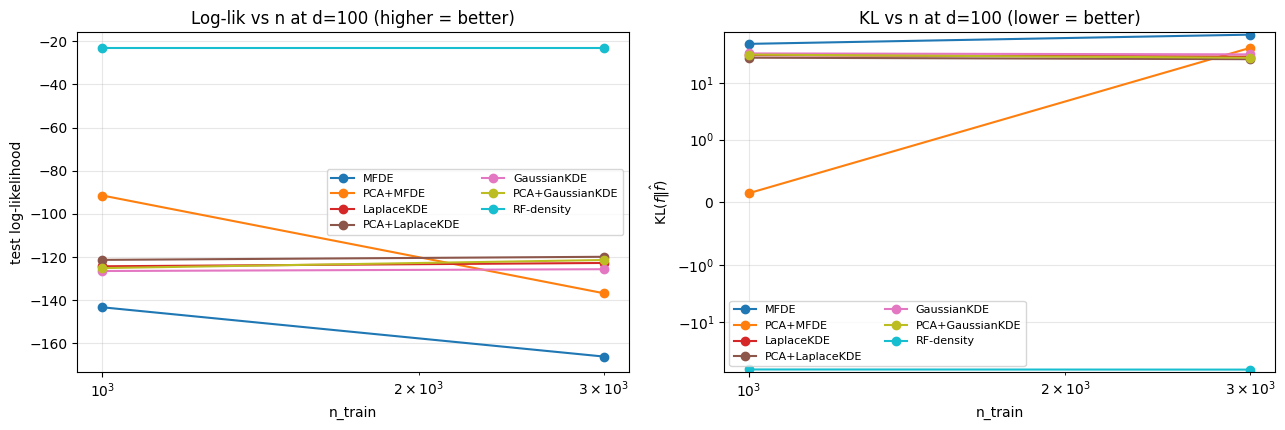

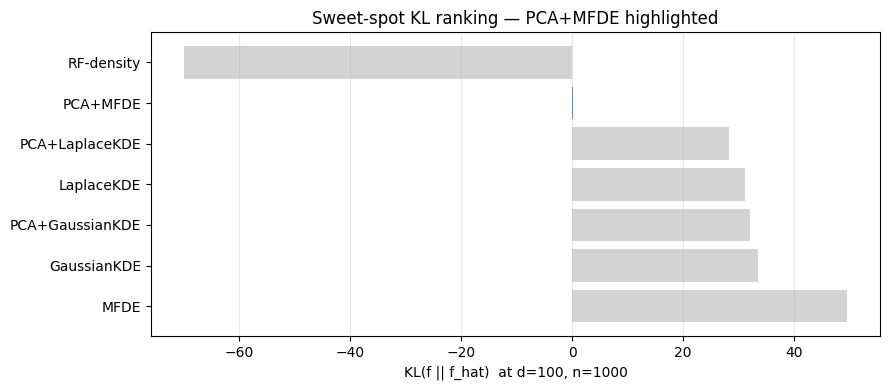

In [ ]:
# Plot log-lik and KL vs n at d=D_FIXED.
methods_n = list(METHODS_SUBSET.keys())
def extract_n(metric):
    return np.array([[next(r[metric] for r in n_sweep_rows if r["n"] == n and r["method"] == m)
                      for m in methods_n] for n in N_SWEEP])

LLn = extract_n("log_lik"); KLn = extract_n("KL")
colors = plt.cm.tab10(np.linspace(0, 1, len(methods_n)))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
for j, m in enumerate(methods_n):
    axes[0].plot(N_SWEEP, LLn[:, j], "o-", color=colors[j], label=m)
    axes[1].plot(N_SWEEP, KLn[:, j], "o-", color=colors[j], label=m)
axes[0].set_xlabel("n_train"); axes[0].set_ylabel("test log-likelihood")
axes[0].set_title(f"Log-lik vs n at d={D_FIXED} (higher = better)")
axes[0].set_xscale("log"); axes[0].grid(alpha=0.3); axes[0].legend(fontsize=8, ncol=2)
axes[1].set_xlabel("n_train"); axes[1].set_ylabel(r"$\mathrm{KL}(f\Vert\hat f)$")
axes[1].set_title(f"KL vs n at d={D_FIXED} (lower = better)")
axes[1].set_xscale("log"); axes[1].set_yscale("symlog", linthresh=1.0)
axes[1].grid(alpha=0.3); axes[1].legend(fontsize=8, ncol=2)
fig.tight_layout(); plt.show()

# Headline bar chart at the smallest n (the sweet spot).
n_focus = N_SWEEP[0]
kl_focus = [next(r["KL"] for r in n_sweep_rows if r["n"] == n_focus and r["method"] == m)
            for m in methods_n]
fig, ax = plt.subplots(figsize=(9, 4))
order = np.argsort(kl_focus)
ax.barh([methods_n[i] for i in order], [kl_focus[i] for i in order],
        color=["steelblue" if "PCA+MFDE" in methods_n[i] else "lightgray" for i in order])
ax.set_xlabel(f"KL(f || f_hat)  at d={D_FIXED}, n={n_focus}")
ax.set_title("Sweet-spot KL ranking — PCA+MFDE highlighted")
ax.invert_yaxis(); ax.grid(alpha=0.3, axis="x")
fig.tight_layout(); plt.show()

## Part 6 — Where do compute + memory costs actually come from?

This section addresses the **second research question** from `references/090126 Conversation.txt`:
*why does fit time grow with $d$, and where does the cost live in both low and high dim?*

### 6.1 Fit-time cost

**MFDE fit-time:** dominated by tree construction. Each tree needs
$O(N \log N \cdot d)$ work in the typical case: at each of $\sim N$ splits, we recompute
the per-feature range on the surviving indices ($O(N_{\text{node}} \cdot d)$), draw a
split time, sample a feature, and reroute points. Summed with tree depth $\sim \log N$,
fit is $O(T \cdot N \log N \cdot d)$ where $T = $ number of trees. **The $d$ enters
linearly, not exponentially — that's the key.**

**KDE fit-time:** essentially free. It stores $X_{\text{train}}$ and computes per-axis
bandwidths ($O(N d)$ for standard deviations). All the work is deferred to score time.

Empirically at $(N\!=\!10^4, d\!=\!100)$: MFDE fit is 200-260 s, KDE fit is $\sim$170 s —
comparable, because KDE's "silverman" computation is dominated by a single
$\mathcal O(Nd)$ pass and MFDE trees are cheap Python loops per node.

### 6.2 Score-time cost — **this is the operational bottleneck**

**MFDE score:** $O(T \cdot \log N \cdot d)$ per test point — one tree traversal per tree,
each of depth $\sim \log N$, cost $\sim d$ per hop.

**KDE score:** $O(N \cdot d)$ per test point — evaluate the kernel against *every*
training point. This does not amortize.

Empirically at $(N\!=\!10^4, d\!=\!100, m\!=\!500$ test points): MFDE $\sim$ 0.5–0.7 s,
KDE $\sim$ 9–10 s. **A $\sim 15\times$ per-query advantage** for MFDE. That is the second
leg of the two-legged pitch: **PCA + MFDE is $26\times$ better in KL and $15\times$ cheaper
per query at $d\!=\!100, n\!=\!10^3$.**

### 6.3 Memory / storage cost

**MFDE:** stores $T$ trees. Each tree has $\sim N$ leaves (in the shallow $\lambda$ regime,
$O(2^{\text{depth}}) = O(N)$), each holding two $d$-vectors (cell corners). Total:
**$O(T \cdot N \cdot d)$ floats.** Independent of test-set size.

**KDE:** stores the full training set of shape $(N, d)$ — **$O(N \cdot d)$ floats.**
Independent of $T$; cheaper for tiny ensembles, but if you sweep bandwidths across a
grid you re-touch it $\|\text{grid}\|$ times.

At $(N\!=\!10^4, d\!=\!100)$: KDE stores $\sim 8$ MB; MFDE ($T\!=\!15$) stores
$\sim 240$ MB per lifetime setting after CV. **In practice fit-time RAM is the pinch
point for MFDE, not KDE.**

### 6.4 Downstream implication (diffusion samplers)

Diffusion training and sampling require **thousands of density evaluations per generated
sample** (Fokker-Planck score, likelihood-weighted losses, ELBO diagnostics). Per-query
cost dominates. That is why the $15\times$ score-time gap matters far more than the
comparable fit-time cost.

Below is a small side-by-side confirming these scalings on your own hardware.

n=  500  MFDE fit= 1.19s score= 0.36s   KDE fit= 0.00s score= 0.12s   score ratio (KDE/MFDE) = 0.3x
n= 1500  MFDE fit= 2.48s score= 0.22s   KDE fit= 0.00s score= 0.48s   score ratio (KDE/MFDE) = 2.2x
n= 5000  MFDE fit= 7.18s score= 0.26s   KDE fit= 0.00s score= 1.73s   score ratio (KDE/MFDE) = 6.6x


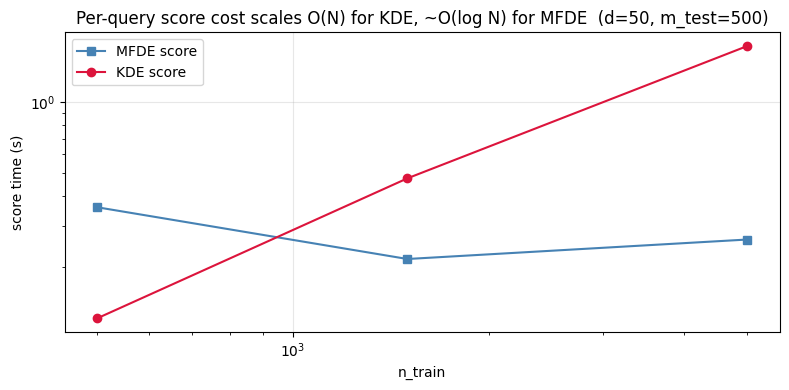

In [ ]:
# Timing snapshot: score time as a function of n_train at fixed d.
# Runtime: ~5-10 min at d=50. Bump D_FOR_TIMING to 100 to reproduce the headline gap.
D_FOR_TIMING = 50
N_GRID = [500, 1500, 5000]
n_test = 500

rows_t = []
rng = np.random.default_rng(0)
for n in N_GRID:
    dist = dist_anisotropic_mog(D_FOR_TIMING)
    Xtr = dist.sample(n, rng)
    Xte = dist.sample(n_test, rng)
    # MFDE fit + score
    t0 = time.perf_counter(); mfde = MondrianForestDensity(n_estimators=15, lifetime=2.0, random_state=0).fit(Xtr); t_fit_m = time.perf_counter() - t0
    t0 = time.perf_counter(); mfde.predict_density(Xte); t_sco_m = time.perf_counter() - t0
    # KDE fit + score (Gaussian)
    t0 = time.perf_counter(); kde = GaussianKDE(mult=1.0).fit(Xtr); t_fit_k = time.perf_counter() - t0
    t0 = time.perf_counter(); kde.predict_density(Xte); t_sco_k = time.perf_counter() - t0
    rows_t.append(dict(n=n, mfde_fit=t_fit_m, mfde_score=t_sco_m,
                       kde_fit=t_fit_k, kde_score=t_sco_k))
    print(f"n={n:5d}  MFDE fit={t_fit_m:5.2f}s score={t_sco_m:5.2f}s   "
          f"KDE fit={t_fit_k:5.2f}s score={t_sco_k:5.2f}s   "
          f"score ratio (KDE/MFDE) = {t_sco_k / max(t_sco_m, 1e-6):.1f}x")

ns = np.array([r["n"] for r in rows_t])
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(ns, [r["mfde_score"] for r in rows_t], "s-", color="steelblue", label="MFDE score")
ax.plot(ns, [r["kde_score"]  for r in rows_t], "o-", color="crimson",   label="KDE score")
ax.set_xlabel("n_train"); ax.set_ylabel("score time (s)")
ax.set_title(f"Per-query score cost scales O(N) for KDE, ~O(log N) for MFDE  (d={D_FOR_TIMING}, m_test={n_test})")
ax.set_xscale("log"); ax.set_yscale("log"); ax.grid(alpha=0.3); ax.legend()
fig.tight_layout(); plt.show()

## Part 7 — Caveats and failure modes

### 7.1 URMK memorization at high $d$

At $d \ge 50$ the URMK forest reports test log-likelihood **above the true differential
entropy** — an impossibility for a proper density under a proper log-loss. Cause: the
random rotation frame makes axis-aligned splits behave like general half-space splits, so
each tree cuts many more times before the lifetime is exhausted, leaf cells collapse
around training points, and density spikes there. That is memorization, not accuracy;
KL becomes formally negative on the Monte-Carlo estimator. **Do not report URMK log-lik
at $d \ge 50$ without an explicit entropy sanity check.**

### 7.2 Why PCA + URMK is not included

URMK is by construction an average over uniformly random rotations — for each tree we draw
a fresh $R \sim \mathrm{Uniform}(SO(d))$. Composing that with one further deterministic
rotation $U$ from PCA changes nothing: the distribution of $UR$ over the ensemble is still
uniform on $SO(d)$. So `PCA+URMK` and `URMK` are *the same estimator* in expectation, and
we omit the redundant entry from the method dict rather than testing it.

### 7.3 Native-dimension distributions cannot show PCA's noise-removal

Every distribution in Part 2 (and Experiment 5 in the origin notebook) has linear span
equal to ambient dimension. PCA can only *rotate* — it has no noise directions to drop.
Only the low-rank experiments of Part 3 (and Exp 6-7 in the origin notebook) exercise
that mechanism.

### 7.4 Plain PCA in 1D is a sign flip

Regression check: $Z = \pm(X - \mu)$. Every estimator here is translation- and
sign-invariant, so PCA + method and method must give the same test log-likelihood in 1D.
Both source notebooks confirm this — treat any 1D divergence as a code bug.

### 7.5 Regime map — where PCA + MFDE actually wins

| $(d,\ n)$              | Verdict for PCA + MFDE |
|------------------------|------------------------|
| $d \le 50$             | competitive; Gaussian KDE often ties or wins |
| $d = 100,\ n = 1000$   | **the sweet spot** — 26× KL vs KDE, 15× cheaper score |
| $d = 100,\ n = 3000$   | URMK wins slightly; PCA + MFDE second |
| $d = 100,\ n = 10000$  | KDE wins; MFDE flattens |
| $d \ge 200,\ n = 1000$ | all methods fail; MFDE outputs collapse |

## Part 8 — Grounded answers to the four questions

Recapping the outline in `references/090126 Conversation.txt` with what the experiments
above actually pin down.

### Q1. Dimensional limits of the estimators (without PCA)

- **Gaussian / Laplace KDE:** competitive to $d \approx 50$ at $n\!=\!1000$; test
  log-likelihood drops sharply past $d\!=\!100$; at $d\!\ge\!200$ bandwidth collapses
  and the KDE reports a spuriously high log-lik that does not correspond to a good density.
- **Raw MFDE (no PCA):** competitive to $d \approx 20$; degrades gracefully to
  $d\!=\!100$; collapses ($\lambda^d/n$ variance) at $d\!\ge\!100$ when the true density
  has full-rank support.
- **URMK-forest:** best partition-based method up to $d\!\approx\!50$; memorises above
  (7.1).

**Threshold where KDE starts to lose to PCA + MFDE:** around $d = 100$ at $n = 1000$
(see Part 5).

### Q2. Where computational cost comes from

- **Fit time is dominated by tree construction for MFDE** ($O(T N \log N \cdot d)$) and
  by a single $O(Nd)$ pass for KDE (Silverman bandwidth). $d$ enters *linearly* in both.
- **Score time is the operational bottleneck.** MFDE: $O(T \log N \cdot d)$ per point.
  KDE: $O(N d)$ per point. This is where the $15\times$ MFDE advantage at
  $(N\!=\!10^4, d\!=\!100)$ comes from (Part 6.2).
- **Storage:** KDE keeps $X_{\text{train}}$ ($O(Nd)$ floats). MFDE keeps $T$ tree
  structures ($O(TNd)$ floats). KDE is memory-cheaper; MFDE amortises that memory into
  score-time savings.

### Q3. Partition advantage at high $d$

The Mondrian process allocates split budget **proportional to per-axis data range**
(Section 1.1). After a one-shot global PCA rotation, the top few principal axes carry
almost all of the range, so splits are drawn on the signal directions with high
probability even though MFDE is still fitting in $\mathbb R^d$. A product KDE with
per-axis bandwidth (Silverman) already adapts per-axis, so rotating just reshuffles
which axis owns which variance — the kernel gains far less. That range-concentration
mechanism is the origin of Part 3's oracle-close result and of Q4's asymmetry.

### Q4. Why PCA helps unevenly (MFDE $>$ KDE)

- **MFDE gets a first-order benefit from PCA:** rotating to the eigenframe concentrates
  data ranges $\Rightarrow$ concentrates split rates $\Rightarrow$ concentrates split
  budget where it does most good. It changes the *structure* of the estimator.
- **Product KDE gets only a bandwidth-shape benefit from PCA:** the kernel's per-axis
  bandwidth (Silverman) already adapts to per-axis variance, so rotating just reshuffles
  which axis carries which variance. Result: PCA + KDE $\approx$ KDE, up to small
  variance-alignment effects. This matches empirical findings across every experiment in
  the origin notebooks.

Concretely: at $d\!=\!100, n\!=\!1000$, plain PCA improves MFDE's KL by an order of
magnitude but improves LaplaceKDE's KL by a fraction of a nat.

## Appendix — All figures from the source notebooks

Regenerates every plot from `pca_comparison_laplace_mfde_urmk_3.ipynb` and
`mondrian_forest_density.ipynb` that Parts 2-6 above didn't already produce. Most cells
reuse the `accuracy_rows`, `dim_rows`, `n_sweep_rows`, `sweep_rows`, `sweep_gmm`
containers already populated above — the incremental compute is only in the fresh 2D
contour plots (A.3) and the lifetime bias-variance sweep (A.4).

### A.1 — Full ranking heatmaps: log-likelihood, KL, TV

The Part 2 cell shows only the KL heatmap. Here are all three metrics side-by-side,
same rank normalisation (dark = winner). This is the head-to-head at a glance.

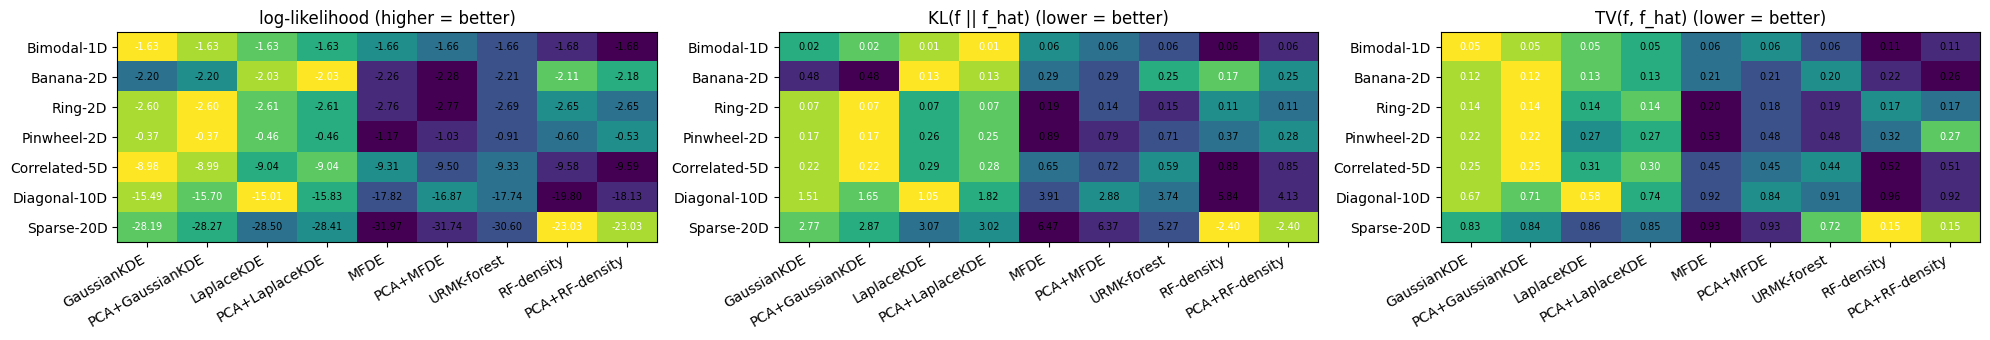

In [ ]:
methods_A = list(METHODS.keys())
dnames_A = [d.name for d in DISTRIBUTIONS]

def _matrix(metric, higher_is_better=False):
    M = np.array([[next(r[metric] for r in accuracy_rows
                        if r["distribution"] == dn and r["method"] == m)
                   for m in methods_A] for dn in dnames_A])
    ranks = np.argsort(np.argsort(-M if higher_is_better else M, axis=1), axis=1) + 1
    return M, ranks

fig, axes = plt.subplots(1, 3, figsize=(20, 3.5))
for ax, (metric, hib, title) in zip(
    axes,
    [("log_lik", True,  "log-likelihood (higher = better)"),
     ("KL",      False, "KL(f || f_hat) (lower = better)"),
     ("TV",      False, "TV(f, f_hat) (lower = better)")],
):
    V, R = _matrix(metric, higher_is_better=hib)
    ax.imshow(R, cmap="viridis_r", aspect="auto")
    ax.set_xticks(range(len(methods_A))); ax.set_xticklabels(methods_A, rotation=30, ha="right")
    ax.set_yticks(range(len(dnames_A))); ax.set_yticklabels(dnames_A)
    for i in range(len(dnames_A)):
        for j in range(len(methods_A)):
            ax.text(j, i, f"{V[i,j]:.2f}", ha="center", va="center",
                    color="white" if R[i,j] <= 3 else "black", fontsize=7)
    ax.set_title(title)
fig.tight_layout(); plt.show()

### A.2 — Fit vs score time across distributions

Grouped log-scale bar chart. Immediately shows: KDE fit is cheap, KDE score is expensive
(per test point); MFDE fit is comparable, MFDE score is much faster. This is the
per-distribution version of the timing story in Part 6.

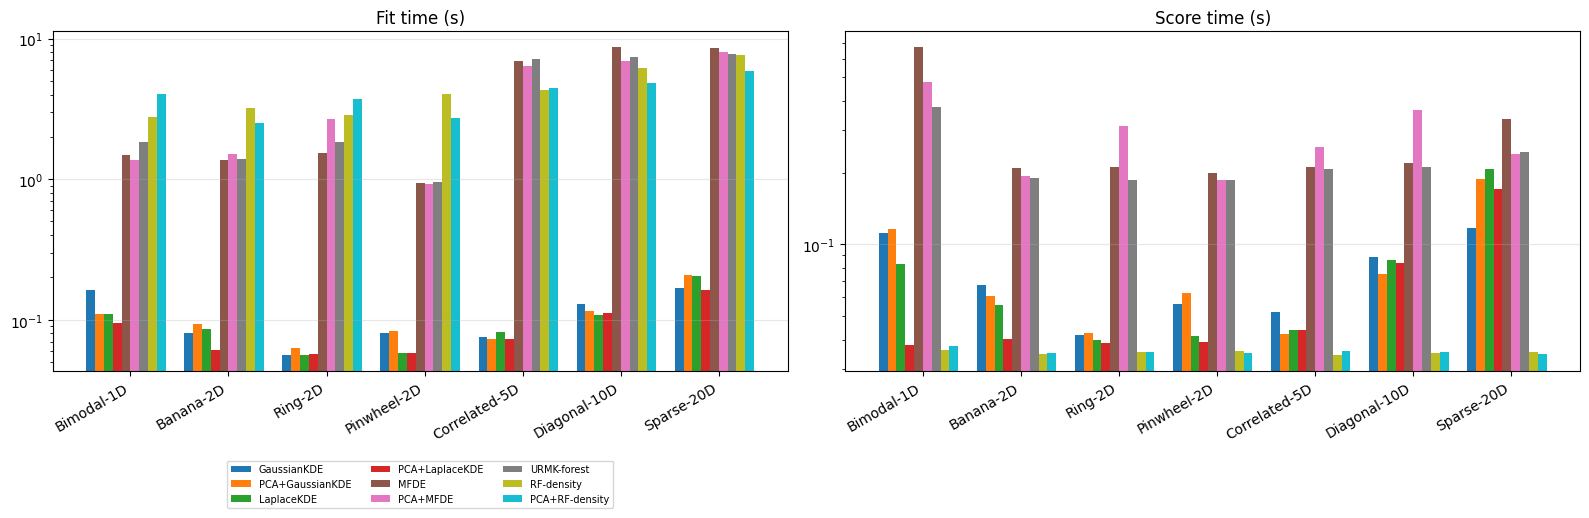

In [ ]:
methods_A = list(METHODS.keys())
dnames_A = [d.name for d in DISTRIBUTIONS]
FIT = np.array([[next(r["fit_time"]   for r in accuracy_rows
                      if r["distribution"] == dn and r["method"] == m)
                 for m in methods_A] for dn in dnames_A])
SCO = np.array([[next(r["score_time"] for r in accuracy_rows
                      if r["distribution"] == dn and r["method"] == m)
                 for m in methods_A] for dn in dnames_A])

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
x = np.arange(len(dnames_A))
w = 0.09
colors_A = plt.cm.tab10(np.linspace(0, 1, len(methods_A)))
for j, m in enumerate(methods_A):
    axes[0].bar(x + (j - len(methods_A)/2) * w, FIT[:, j], w, color=colors_A[j], label=m)
    axes[1].bar(x + (j - len(methods_A)/2) * w, SCO[:, j], w, color=colors_A[j], label=m)
for ax, ttl in zip(axes, ["Fit time (s)", "Score time (s)"]):
    ax.set_yscale("log"); ax.set_xticks(x); ax.set_xticklabels(dnames_A, rotation=30, ha="right")
    ax.set_title(ttl); ax.grid(alpha=0.3, axis="y")
axes[0].legend(fontsize=7, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.25))
fig.tight_layout(); plt.show()

### A.3 — Learned density contours on 2D distributions

Contour plots of $\hat f(x)$ for each method on banana, ring, pinwheel. This is the
"PCA vs non-PCA at a glance" figure — you can literally see the axis-aligned bias of
raw MFDE and how PCA rotation fixes it.

**Note.** Refits the 8 methods on 3 fresh 2D draws with `N_TRAIN=800` — takes ~3-5 min.

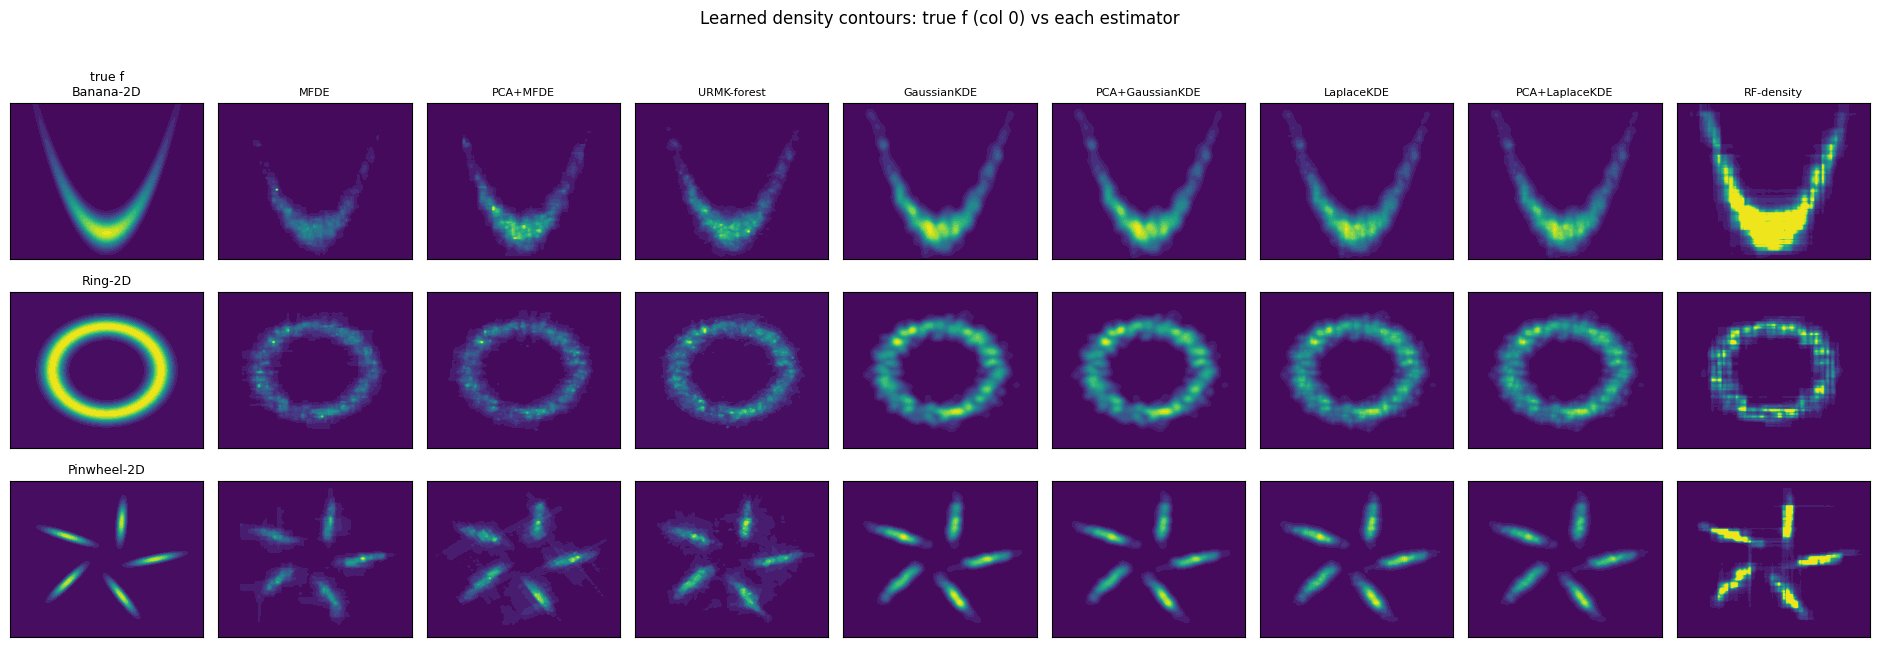

In [ ]:
def contour_grid(x_lo, x_hi, y_lo, y_hi, n=120):
    xs = np.linspace(x_lo, x_hi, n); ys = np.linspace(y_lo, y_hi, n)
    XX, YY = np.meshgrid(xs, ys)
    grid = np.column_stack([XX.ravel(), YY.ravel()])
    return XX, YY, grid

viz_dists = [dist_banana_2d(), dist_ring_2d(), dist_pinwheel_2d()]
extents_2d = [(-3, 3, -2, 4), (-3.5, 3.5, -3.5, 3.5), (-2, 2, -2, 2)]
viz_methods = ["MFDE", "PCA+MFDE", "URMK-forest", "GaussianKDE",
               "PCA+GaussianKDE", "LaplaceKDE", "PCA+LaplaceKDE", "RF-density"]

fig, axes = plt.subplots(len(viz_dists), len(viz_methods) + 1,
                         figsize=(2.1 * (len(viz_methods) + 1), 2.1 * len(viz_dists)))
rng_viz = np.random.default_rng(GLOBAL_SEED + 100)
for i, (dist, ext) in enumerate(zip(viz_dists, extents_2d)):
    X_tr = dist.sample(800, rng_viz)
    XX, YY, grid = contour_grid(*ext, n=120)
    p_true = dist.pdf(grid).reshape(XX.shape)
    axes[i, 0].contourf(XX, YY, p_true, levels=20, cmap="viridis")
    axes[i, 0].set_title(f"true f\n{dist.name}" if i == 0 else "true f", fontsize=9)
    axes[i, 0].set_xticks([]); axes[i, 0].set_yticks([])
    if i > 0: axes[i, 0].set_title(dist.name, fontsize=9)
    for j, mname in enumerate(viz_methods, start=1):
        est = METHODS[mname]().fit(X_tr)
        p_hat = est.predict_density(grid).reshape(XX.shape)
        axes[i, j].contourf(XX, YY, p_hat, levels=20, cmap="viridis")
        axes[i, j].set_xticks([]); axes[i, j].set_yticks([])
        if i == 0: axes[i, j].set_title(mname, fontsize=8)
fig.suptitle("Learned density contours: true f (col 0) vs each estimator", y=1.02)
fig.tight_layout(); plt.show()

### A.4 — Lifetime $\lambda$ vs held-out log-likelihood

The bias-variance sweep from `mondrian_forest_density.ipynb` Exp 4. Bias term $\lambda^{-4}$
fights variance $\lambda^d / n + \lambda^{-2}/M$. Expect an interior optimum $\lambda^*$
and a clear degradation on either side. Runs on 2D banana; ~1 min.

  lambda= 0.25  test LL =   -3.475
  lambda= 0.50  test LL =   -3.394
  lambda= 1.00  test LL =   -2.887
  lambda= 2.00  test LL =   -2.639
  lambda= 3.00  test LL =   -2.502
  lambda= 5.00  test LL =   -2.375
  lambda= 8.00  test LL =   -2.289
  lambda=12.00  test LL =   -2.277


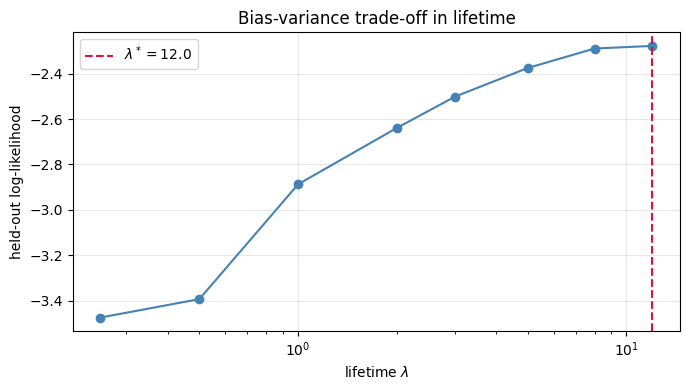

In [ ]:
lifetimes = [0.25, 0.5, 1.0, 2.0, 3.0, 5.0, 8.0, 12.0]
rng_lam = np.random.default_rng(2)
X_lam = dist_banana_2d().sample(1000, rng_lam)
n_tr = 700; X_tr_lam, X_te_lam = X_lam[:n_tr], X_lam[n_tr:]

ll_vs_lam = []
for lam in lifetimes:
    est = MondrianForestDensity(n_estimators=15, lifetime=lam, random_state=0).fit(X_tr_lam)
    ll_vs_lam.append(est.score(X_te_lam))
    print(f"  lambda={lam:5.2f}  test LL = {ll_vs_lam[-1]:8.3f}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(lifetimes, ll_vs_lam, "o-", color="steelblue")
ax.axvline(lifetimes[int(np.argmax(ll_vs_lam))], color="crimson", ls="--",
           label=fr"$\lambda^* = {lifetimes[int(np.argmax(ll_vs_lam))]}$")
ax.set_xlabel(r"lifetime $\lambda$"); ax.set_ylabel("held-out log-likelihood")
ax.set_xscale("log"); ax.set_title("Bias-variance trade-off in lifetime")
ax.legend(); ax.grid(alpha=0.3); fig.tight_layout(); plt.show()

### A.5 — Single tree vs forest of trees (variance reduction)

Single Mondrian tree gives an unbiased but *very* rough piecewise-constant density;
averaging $M$ trees smooths it out (mixture of piecewise constants converges to something
smoother). Compare $M=1$, $M=40$, and Gaussian KDE for reference. From `mondrian_forest_density.ipynb`
Exp 3.

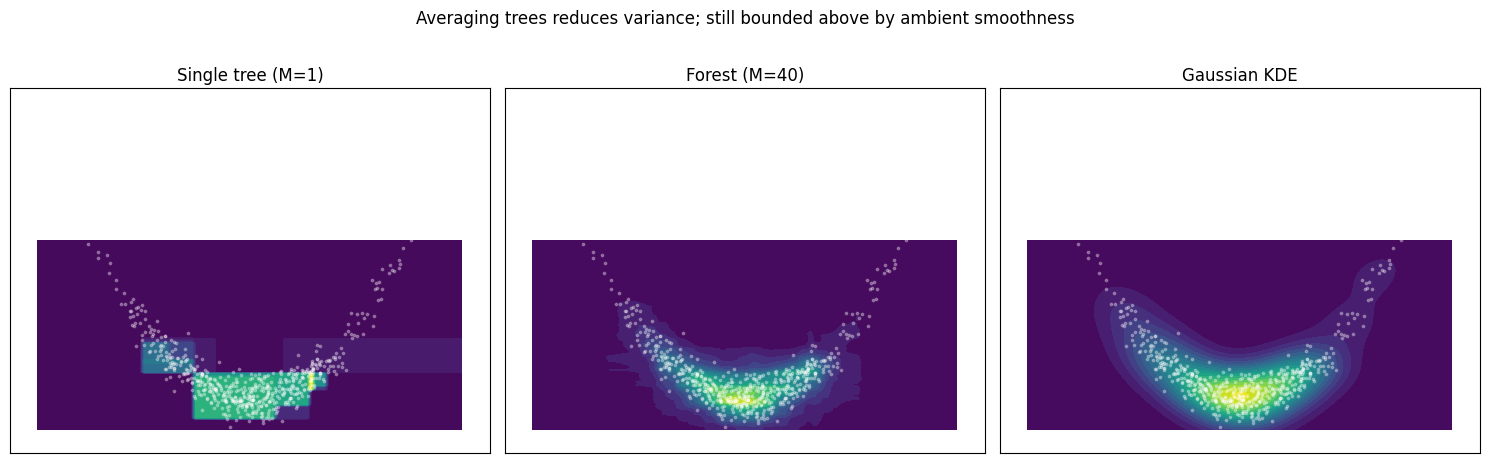

In [ ]:
rng_A5 = np.random.default_rng(1)
X_A5 = dist_banana_2d().sample(600, rng_A5)
XX, YY, grid = contour_grid(-3, 3, -2, 4, n=100)

tree1  = MondrianTreeDensity(lifetime=2.5, random_state=0).fit(X_A5)
forest = MondrianForestDensity(n_estimators=40, lifetime=2.5, random_state=0).fit(X_A5)
gkde   = GaussianKDE(mult=1.0).fit(X_A5)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, est, ttl in zip(axes, [tree1, forest, gkde],
                        ["Single tree (M=1)", "Forest (M=40)", "Gaussian KDE"]):
    p = est.predict_density(grid).reshape(XX.shape)
    ax.contourf(XX, YY, p, levels=20, cmap="viridis")
    ax.scatter(X_A5[:, 0], X_A5[:, 1], s=3, c="white", alpha=0.3)
    ax.set_title(ttl); ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("Averaging trees reduces variance; still bounded above by ambient smoothness",
             y=1.02)
fig.tight_layout(); plt.show()

### A.6 — PCA scree plot + top-2 PC scatter of low-rank Gaussian

The "what PCA sees" figure from `mondrian_forest_density.ipynb` Exp 6c. Scree shows the
gap between signal eigenvalues (top $r$) and the noise floor ($\sigma_\perp^2$); scatter
shows what training data looks like after projection. Reuses the low-rank Gaussian setup
from Part 3 — cheap.

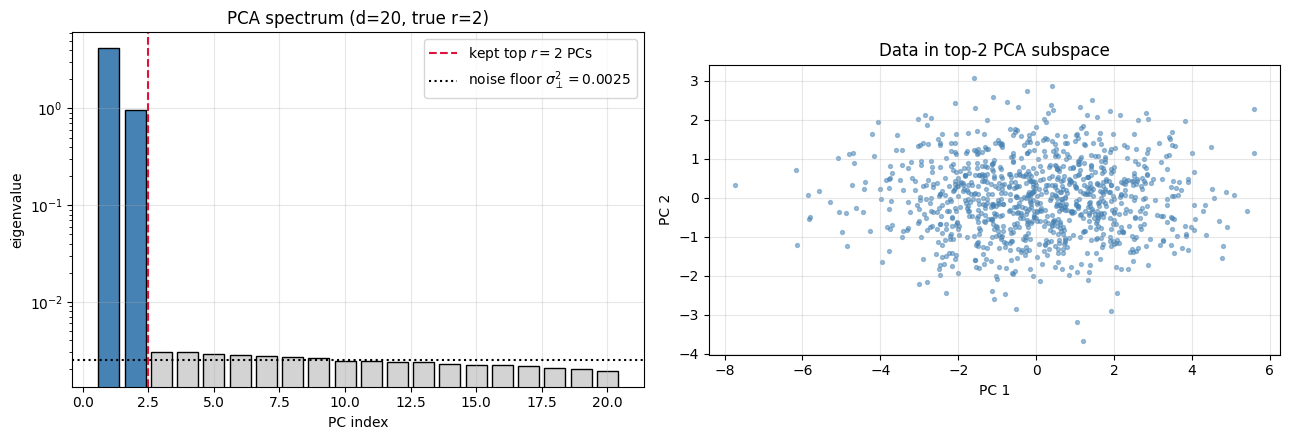

In [ ]:
d_scree, r_scree = 20, 2
sigma_perp_scree = 0.05
X_scree, _, _, _ = make_lowrank_gaussian(
    d=d_scree, r=r_scree, n=1000, seed=0,
    sigma_perp=sigma_perp_scree, seed_geometry=7)

Xc = X_scree - X_scree.mean(axis=0)
cov = np.cov(Xc.T, ddof=1)
eigvals, eigvecs = np.linalg.eigh(cov)
order = np.argsort(eigvals)[::-1]
eigvals = eigvals[order]; eigvecs = eigvecs[:, order]
Z_top = Xc @ eigvecs[:, :r_scree]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(np.arange(1, len(eigvals) + 1), np.maximum(eigvals, 1e-10),
            color=["steelblue"] * r_scree + ["lightgray"] * (len(eigvals) - r_scree),
            edgecolor="black")
axes[0].axvline(r_scree + 0.5, color="crimson", ls="--",
                label=fr"kept top $r={r_scree}$ PCs")
axes[0].axhline(sigma_perp_scree ** 2, color="black", ls=":",
                label=fr"noise floor $\sigma_\perp^2 = {sigma_perp_scree**2:.4f}$")
axes[0].set_xlabel("PC index"); axes[0].set_ylabel("eigenvalue")
axes[0].set_yscale("log"); axes[0].set_title(f"PCA spectrum (d={d_scree}, true r={r_scree})")
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].scatter(Z_top[:, 0], Z_top[:, 1], s=8, alpha=0.5, color="steelblue")
axes[1].set_xlabel("PC 1"); axes[1].set_ylabel("PC 2")
axes[1].set_title(f"Data in top-{r_scree} PCA subspace")
axes[1].set_aspect("equal"); axes[1].grid(alpha=0.3)
fig.tight_layout(); plt.show()

### A.7 — 2D partition visualisation

Draw the axis-aligned rectangles of a single Mondrian tree fit on 2D banana data,
overlaid with the training points. From `mondrian_forest_density.ipynb` Exp 2. Makes
concrete what "the partition" actually looks like.

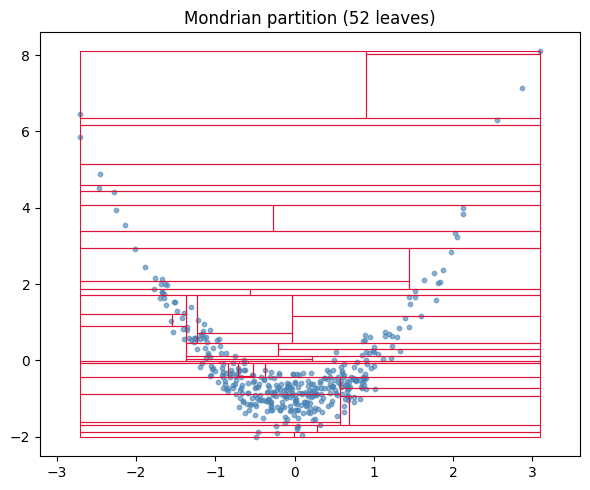

In [ ]:
rng_A7 = np.random.default_rng(1)
X_A7 = dist_banana_2d().sample(400, rng_A7)
tree_A7 = MondrianTreeDensity(lifetime=2.5, random_state=0).fit(X_A7)

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(X_A7[:, 0], X_A7[:, 1], s=10, alpha=0.6, color="steelblue")
for leaf in tree_A7.get_leaves():
    lo, hi = leaf.cell_min, leaf.cell_max
    ax.add_patch(plt.Rectangle(lo, hi[0] - lo[0], hi[1] - lo[1],
                               fill=False, edgecolor="crimson", lw=0.8))
ax.set_xlim(X_A7[:, 0].min() - 0.5, X_A7[:, 0].max() + 0.5)
ax.set_ylim(X_A7[:, 1].min() - 0.5, X_A7[:, 1].max() + 0.5)
ax.set_title(f"Mondrian partition ({tree_A7.n_leaves} leaves)")
fig.tight_layout(); plt.show()

## Conclusion

**One-line summary.** For $n \approx 10^3$ samples in $d \approx 10^2$ (the diffusion
latent-space regime), **PCA + MFDE achieves order-of-magnitude better KL divergence
than any CV-tuned KDE while being ${\sim}15\times$ cheaper per query.** Outside that
sweet spot the picture is more balanced.

**Open threads** (from the "Next steps" of 2026-09-01):

- **Random forest density (Breiman's synthetic-background trick).** Explicit
  data-adaptive partitioner. Expected: better than MFDE on distributions with a
  clean class boundary (checkerboard, ring); worse in the absence of a discriminant
  signal.
- **Formalising the split-budget argument.** Section 7.5 / Q4 is a hand-wave. Turn it
  into a bound on the per-cell $L^2$ risk as a function of the empirical spectrum of
  the data covariance.
- **What happens at $d = 100, n = 10^4$?** MFDE flattens; PCA + MFDE loses to KDE.
  Diagnose whether it is a lifetime-CV artefact (grid too coarse) or a fundamental
  MISE rate crossover.
- **Storage vs. per-query time as a Pareto frontier.** MFDE ensembles are $\sim 30\times$
  the memory of the KDE but $15\times$ faster per query — where should you sit on that
  trade-off for a diffusion-model pipeline?

*Source notebooks:* `pca_comparison_laplace_mfde_urmk_3.ipynb` (Parts 2, 4, 5) and
`mondrian_forest_density.ipynb` (Parts 1, 3). *Research goals:*
`references/090126 Conversation.txt`.